kak saya kerjakan nomor 2 dan 3 pake indo ya kak baru liat grup taunya boleh pake indo hehehehe

### Problem Understanding

**Context**


Kriminalitas di Bangladesh menunjukkan pola yang kompleks dan dipengaruhi oleh berbagai faktor, seperti waktu kejadian, lokasi, kondisi lingkungan, struktur populasi, serta infrastruktur sosial. Pendekatan kepolisian yang masih dominan bersifat reaktif dan kurang didukung oleh analisis data yang sistematis, sehingga menyulitkan dalam mengidentifikasi tren kejahatan serta mengalokasikan sumber daya secara efektif. Seiring dengan semakin kompleks dan multidimensinya data kriminalitas, diperlukan pendekatan berbasis data (data-driven approach) untuk mendukung perumusan kebijakan keamanan dan pengambilan keputusan strategis yang berbasis bukti (evidence-based decision making).

**Problem Statement**

Meskipun data kriminalitas historis tersedia, belum terdapat kerangka analisis terintegrasi yang mampu mengidentifikasi pola kejahatan, memahami faktor-faktor yang memengaruhinya, serta mengelompokkan wilayah berdasarkan karakteristik kriminalitas. Hal ini membatasi efektivitas strategi pencegahan, penerapan predictive policing, dan optimalisasi alokasi sumber daya kepolisian.

**Project Goals**

Proyek ini bertujuan untuk mengeksplorasi pola kriminalitas melalui Exploratory Data Analysis (EDA), mengelompokkan wilayah menggunakan metode K-Means clustering berdasarkan karakteristik kejahatan, membentuk profil setiap klaster guna memahami karakteristik kriminalitas wilayah, serta menghasilkan insight yang dapat mendukung penerapan strategi kepolisian berbasis data (data-driven policing) dalam perencanaan kebijakan keamanan dan ketertiban masyarakat.

In [383]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [384]:
df = pd.read_csv('Bangladesh_Crime_Dataset_A.csv',sep=',')
df.head()

,Unnamed: 0,incident_month,incident_week,incident_weekday,weekend,part_of_the_day,incident_district,incident_division,precip,visibility,...,average_household_size,density_per_kmsq,literacy_rate,religious_institution,playground,park,police_station,school,college,crime
0,0,7.0,29,wednesday,0,morning,dhaka,dhaka,6.1,10,...,8.42,30551.0,74.6,4289,99,17,60,242,64,murder
1,1,1.0,2,wednesday,0,night,dhaka,dhaka,0.0,10,...,8.42,30551.0,74.6,4289,99,17,60,242,64,murder
2,2,1.0,4,tuesday,0,night,dhaka,dhaka,0.0,10,...,8.42,30551.0,74.6,4289,99,17,60,242,64,murder
3,3,3.0,9,friday,1,night,dhaka,dhaka,0.0,10,...,8.42,30551.0,74.6,4289,99,17,60,242,64,murder
4,4,8.0,34,thursday,0,night,dhaka,dhaka,21.9,9,...,8.42,30551.0,74.6,4289,99,17,60,242,64,murder


In [385]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6574 entries, 0 to 6573
Data columns (total 26 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              6574 non-null   int64  
 1   incident_month          5917 non-null   float64
 2   incident_week           6574 non-null   int64  
 3   incident_weekday        6574 non-null   object 
 4   weekend                 6574 non-null   int64  
 5   part_of_the_day         6457 non-null   object 
 6   incident_district       6246 non-null   object 
 7   incident_division       6574 non-null   object 
 8   precip                  6574 non-null   float64
 9   visibility              6574 non-null   int64  
 10  heatindex               6574 non-null   int64  
 11  season                  6574 non-null   object 
 12  male_population         6574 non-null   int64  
 13  female_population       6574 non-null   int64  
 14  total_population        6574 non-null   

In [386]:
# Numerical statistical summary
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,6574.0,3.286500e+03,1.897895e+03,0.000000e+00,1643.25,3286.50,4929.75,6.573000e+03
incident_month,5917.0,6.210749e+00,3.319075e+00,1.000000e+00,3.00,6.00,9.00,1.200000e+01
incident_week,6574.0,2.519395e+01,1.451796e+01,1.000000e+00,13.00,25.00,37.00,5.300000e+01
weekend,6574.0,2.738059e-01,4.459445e-01,0.000000e+00,0.00,0.00,1.00,1.000000e+00
precip,6574.0,6.187998e+00,1.199000e+01,0.000000e+00,0.00,0.80,7.50,2.046000e+02
visibility,6574.0,9.488287e+00,9.227419e-01,4.000000e+00,9.00,10.00,10.00,1.000000e+01
heatindex,6574.0,3.159766e+01,5.502593e+00,1.500000e+01,27.00,33.00,36.00,4.300000e+01
male_population,6574.0,8.936342e+05,1.605205e+06,1.132000e+04,131930.00,187229.00,391707.00,4.931802e+06
female_population,6574.0,7.544586e+05,1.284180e+06,1.124700e+04,133996.00,187017.00,381157.25,3.974237e+06
total_population,6574.0,1.648104e+06,2.889245e+06,2.287100e+04,265276.00,376550.00,775733.00,8.906039e+06


In [387]:
#Categorical statistical summary
df.describe(include=object)

,incident_weekday,part_of_the_day,incident_district,incident_division,season,crime
count,6574,6457,6246,6574,6574,6574
unique,7,5,64,192,3,6
top,tuesday,night,dhaka,dhaka,rainy,murder
freq,1010,3179,1115,1806,2850,1518


**Secara umum, data menunjukkan bahwa kriminalitas di Bangladesh memiliki pola yang dipengaruhi oleh faktor temporal, spasial, lingkungan, dan sosial-demografis. Kejahatan cenderung terkonsentrasi di wilayah urban padat penduduk, lebih dominan terjadi pada malam hari, serta menunjukkan variasi berdasarkan musim dan hari dalam seminggu. Terdapat ketimpangan signifikan antar wilayah dalam aspek kepadatan penduduk, struktur demografis, dan infrastruktur publik, yang mengindikasikan adanya perbedaan tingkat risiko kriminalitas. Pola-pola ini menunjukkan bahwa dataset sangat relevan untuk analisis lanjutan berbasis clustering guna segmentasi wilayah dan perumusan strategi kepolisian berbasis data.**

**Check Missing Value**

In [388]:
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100

missing_df = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": missing_percent
}).sort_values(by="Missing Percentage", ascending=False)

missing_df

,Missing Count,Missing Percentage
incident_month,657,9.993915
incident_district,328,4.989352
literacy_rate,328,4.989352
part_of_the_day,117,1.779738
Unnamed: 0,0,0.000000
gender_ration,0,0.000000
college,0,0.000000
school,0,0.000000
police_station,0,0.000000
park,0,0.000000


**Secara umum, dataset memiliki tingkat kelengkapan data yang baik, karena sebagian besar variabel tidak mengandung missing value. Missing value hanya terkonsentrasi pada beberapa fitur utama, yaitu incident_month (~10%), incident_district (~5%), literacy_rate (~5%), dan part_of_the_day (~1.8%). Pola ini menunjukkan bahwa missing data bersifat parsial dan tidak tersebar merata pada seluruh variabel, sehingga tidak mengganggu integritas dataset secara keseluruhan. dan kita akan impute missing value karena setiap baris bermakna**

**Check Duplicate Data**

In [389]:
df.duplicated().sum()

0

**Check Inconsistent Data**

In [390]:
for col in df.columns:
    print(f"Unique values in column '{col}':")
    print(df[col].unique())
    print("\n")

Unique values in column 'Unnamed: 0':
[   0    1    2 ... 6571 6572 6573]


Unique values in column 'incident_month':
[ 7.  1.  3.  8.  2. nan 11.  6.  4.  5.  9. 10. 12.]


Unique values in column 'incident_week':
[29  2  4  9 34  7  1 46 45 36 23 14 31 19 37  3 16 12 44 26 40 21 24 10
  5 11 35 25  8 28 32 30  6 17 20 22 18 49 51 33 43 52 15 27 38 13 42 48
 47 41 39 50 53]


Unique values in column 'incident_weekday':
['wednesday' 'tuesday' 'friday' 'thursday' 'sunday' 'saturday' 'monday']


Unique values in column 'weekend':
[0 1]


Unique values in column 'part_of_the_day':
['morning' 'night' 'evening' 'noon' nan 'afternoon']


Unique values in column 'incident_district':
['dhaka' nan 'gazipur' 'chattogram' 'rajshahi' 'khulna' 'sirajganj'
 'narsingdi' 'lakshmipur' 'manikganj' 'patuakhali' 'jashore' 'sunamganj'
 'bhola' 'satkhira' 'gopalganj' 'habiganj' 'rangpur' 'tangail' 'sylhet'
 'dinajpur' 'kurigram' 'rangamati' 'lalmonirhat' 'barisal' 'brahmanbaria'
 'joypurhat' 'chuadanga' 'ba

**Masalah kita**

1. Missing Value
2. Data yang tidak konsistent / data yang aneh

**Cleaning Data**

kita akan check one by one dan kita akan explore datanya

In [391]:
#sebelum itu kita drop satu kolom yang tidak oenting yaitu Unkown: 0 karena itu uniq value
df = df.drop(columns=["Unnamed: 0"])

**Incident_Mounth**

In [392]:
df['incident_month'].describe()

count    5917.000000
mean        6.210749
std         3.319075
min         1.000000
25%         3.000000
50%         6.000000
75%         9.000000
max        12.000000
Name: incident_month, dtype: float64

In [393]:
df['incident_month'].value_counts()

incident_month
8.0     579
5.0     547
4.0     541
1.0     537
3.0     519
7.0     515
10.0    503
6.0     497
2.0     483
9.0     481
11.0    368
12.0    347
Name: count, dtype: int64

In [394]:
df['incident_month'].isna().sum()

657

**Datanya aman tapi ada missing Value, dan juga nilai dari data ini hanya angka 1-12 yaitu bulan**

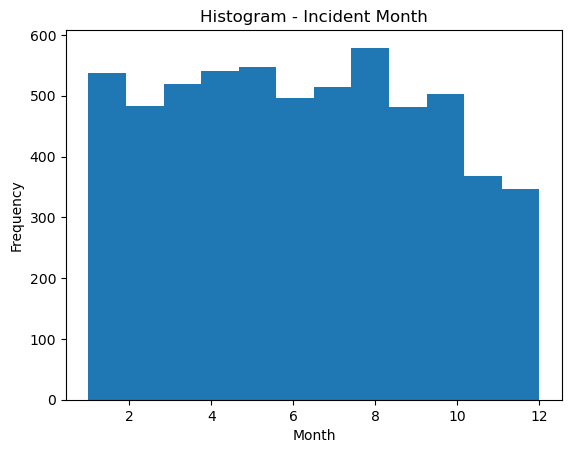

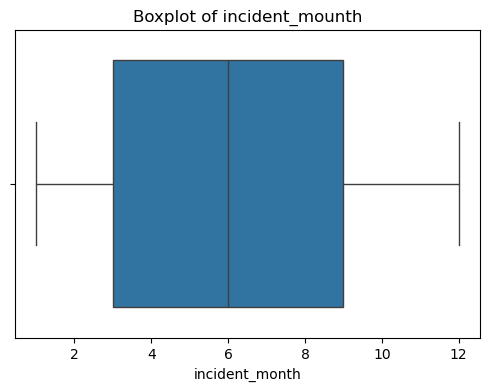

In [395]:
#Explore the data
#histogram
plt.figure()
plt.hist(df["incident_month"].dropna(), bins=12)
plt.title("Histogram - Incident Month")
plt.xlabel("Month")
plt.ylabel("Frequency")
plt.show()

# boxplot
plt.figure(figsize=(6,4))
sns.boxplot(x=df["incident_month"])
plt.title("Boxplot of incident_mounth")
plt.show()

**Distribusi kejadian kriminal berdasarkan incident_month menunjukkan sebaran yang relatif merata sepanjang tahun, tanpa adanya lonjakan ekstrem pada bulan tertentu. Boxplot memperlihatkan median berada di sekitar pertengahan tahun, dengan sebaran data yang simetris dan tanpa outlier yang signifikan. Hal ini mengindikasikan bahwa kriminalitas tidak terpusat pada musim atau bulan spesifik, melainkan terjadi secara konsisten sepanjang tahun, sehingga faktor waktu bulanan bukan merupakan determinan dominan dalam pola kriminalitas dan lebih relevan digunakan sebagai variabel pendukung dalam analisis lanjutan. dan kita akan isi missing value dengan median karena walaupun tidak terdeteksi outliers ini tipe dataya float jadi takutnya kalau di isi dengan mean jadi aneh.**

In [396]:
# Imputasi missing value dengan median
month_median = df["incident_month"].median()
df["incident_month"].fillna(month_median, inplace=True)

In [397]:
df['incident_month'].isna().sum()

0

**Incident week**

In [398]:
df['incident_week'].describe()

count    6574.000000
mean       25.193946
std        14.517965
min         1.000000
25%        13.000000
50%        25.000000
75%        37.000000
max        53.000000
Name: incident_week, dtype: float64

In [399]:
df['incident_week'].value_counts()

incident_week
16    175
33    173
42    159
22    155
19    153
3     151
36    148
6     148
2     148
34    146
15    146
10    145
35    145
7     143
4     143
31    142
30    140
29    139
26    136
25    136
18    133
11    132
13    129
8     129
5     127
37    127
28    126
21    125
17    124
20    124
43    120
41    119
24    118
39    117
12    117
40    117
1     117
23    116
32    115
38    114
14    113
9     106
44    105
46    102
27    102
49     95
50     91
45     90
47     86
51     86
48     82
52     78
53     21
Name: count, dtype: int64

In [400]:
df['incident_week'].isna().sum()

0

**Berdasarkan hasil eksplorasi awal, variabel incident_week memiliki rentang nilai yang valid (1–53), tidak mengandung nilai yang tidak logis, serta tidak ditemukan missing value. Distribusi data menunjukkan bahwa setiap minggu memiliki frekuensi kejadian yang relatif merata, tanpa dominasi ekstrem pada minggu tertentu. Dengan demikian, variabel ini dinyatakan bersih secara struktural dan semantik, sehingga tidak memerlukan proses cleaning atau imputasi tambahan. Tahap analisis selanjutnya difokuskan pada eksplorasi distribusi data menggunakan visualisasi histogram dan boxplot untuk memahami pola sebaran dan karakteristik temporal kejadian kriminal.**

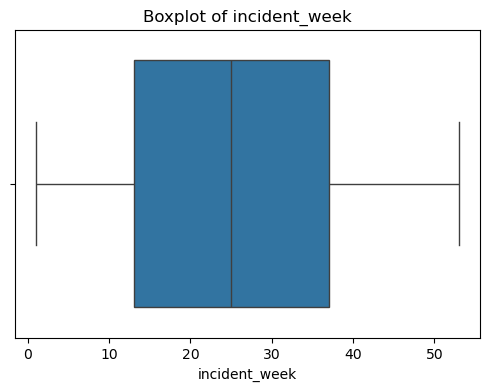

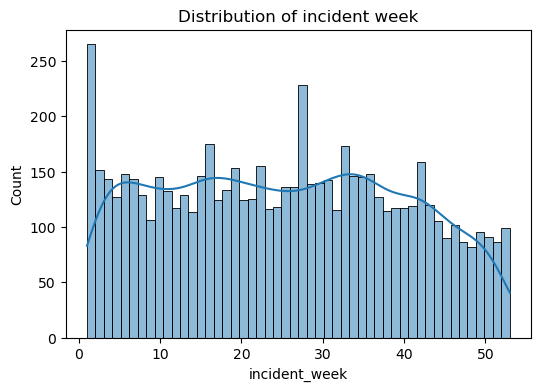

In [401]:
# Explore the data

# Boxplot
plt.figure(figsize=(6,4))
sns.boxplot(x=df["incident_week"])
plt.title("Boxplot of incident_week")
plt.show()

# Histogram
plt.figure(figsize=(6,4))
sns.histplot(df["incident_week"], bins=50, kde=True)
plt.title("Distribution of incident week")
plt.show()

**Visualisasi histogram dan boxplot menunjukkan bahwa distribusi incident_week relatif merata sepanjang minggu ke-1 hingga ke-53, tanpa adanya konsentrasi ekstrem pada minggu tertentu. Boxplot memperlihatkan sebaran data yang simetris dengan median berada di sekitar pertengahan tahun, serta tidak ditemukan outlier yang signifikan. Hal ini mengindikasikan bahwa kejadian kriminal tersebar secara konsisten sepanjang tahun dan tidak terfokus pada periode minggu tertentu, sehingga variabel incident_week bersifat stabil dan representatif sebagai indikator temporal dalam analisis lanjutan.**

**weekend**

In [402]:
df['weekend'].describe()

count    6574.000000
mean        0.273806
std         0.445944
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max         1.000000
Name: weekend, dtype: float64

In [403]:
df['weekend'].value_counts()

weekend
0    4774
1    1800
Name: count, dtype: int64

In [404]:
    df['weekend'].isna().sum()

0

**Variabel weekend merupakan variabel biner (0 = hari kerja, 1 = akhir pekan) dengan domain nilai yang valid (0 dan 1), tanpa adanya missing value maupun nilai tidak logis. Distribusi frekuensi menunjukkan bahwa mayoritas kejadian kriminal terjadi pada hari kerja dibandingkan akhir pekan, namun proporsi kejadian di akhir pekan tetap signifikan. Dengan demikian, variabel weekend dinyatakan bersih secara struktural dan semantik, sehingga tidak memerlukan proses cleaning lanjutan dan dapat langsung digunakan untuk tahap eksplorasi visualisasi data.**

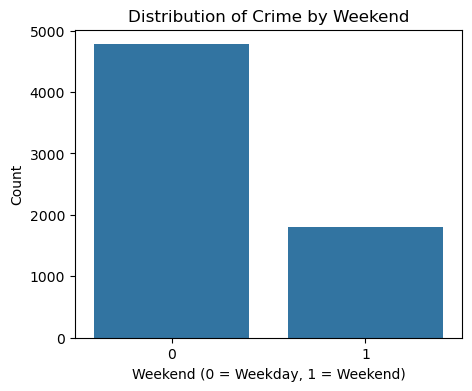

In [405]:
#Explore the data
plt.figure(figsize=(5,4))
sns.countplot(x="weekend", data=df)
plt.title("Distribution of Crime by Weekend")
plt.xlabel("Weekend (0 = Weekday, 1 = Weekend)")
plt.ylabel("Count")
plt.show()

**Distribusi kejadian kriminal menunjukkan bahwa mayoritas insiden terjadi pada hari kerja (weekday) dibandingkan akhir pekan (weekend). Meskipun demikian, jumlah kejadian pada akhir pekan tetap signifikan dan tidak dapat diabaikan. Pola ini mengindikasikan bahwa aktivitas kriminal lebih banyak terjadi seiring dengan tingginya aktivitas sosial dan mobilitas masyarakat pada hari kerja. Variabel weekend dengan demikian relevan sebagai indikator temporal yang penting dalam analisis pola kriminalitas dan perencanaan strategi patroli berbasis waktu.**

**Part of the day**

In [406]:
df['part_of_the_day'].describe()

count      6457
unique        5
top       night
freq       3179
Name: part_of_the_day, dtype: object

In [407]:
df['part_of_the_day'].value_counts()

part_of_the_day
night        3179
morning      1946
noon          517
evening       484
afternoon     331
Name: count, dtype: int64

In [408]:
df['part_of_the_day'].isna().sum()

117

**Variabel part_of_the_day merupakan variabel kategorikal yang merepresentasikan waktu kejadian dalam sehari, dengan kategori utama yaitu morning, noon, afternoon, evening, dan night. Distribusi data menunjukkan bahwa mayoritas kejadian kriminal terjadi pada malam hari (night), diikuti oleh pagi hari (morning), sementara siang (afternoon), sore (evening), dan afternoon memiliki frekuensi yang lebih rendah. Ditemukan sejumlah kecil missing value dan ada data yang tidak konsisten noon harusnya masuk ke afternoon**

In [409]:
# Normalisasi kategori
df["part_of_the_day"] = df["part_of_the_day"].replace({
    "noon": "afternoon"
})

# Lihat mode
part_mode = df["part_of_the_day"].mode()[0]

# Isi missing value dengan mode
df["part_of_the_day"].fillna(part_mode, inplace=True)

In [410]:
df['part_of_the_day'].isna().sum()

0

In [411]:
df['part_of_the_day'].value_counts()

part_of_the_day
night        3296
morning      1946
afternoon     848
evening       484
Name: count, dtype: int64

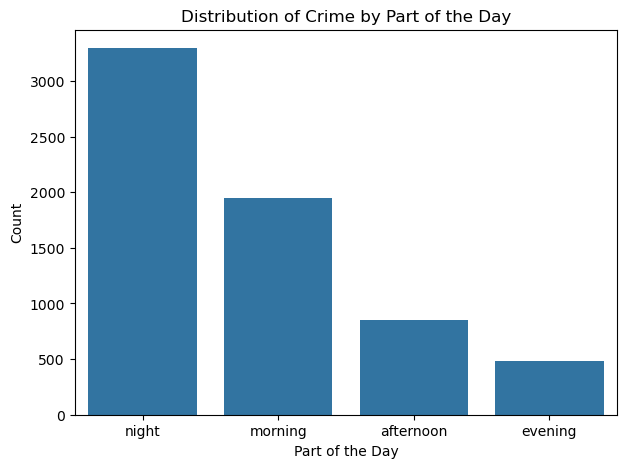

In [412]:
# explore the data

plt.figure(figsize=(7,5))
sns.countplot(
    x="part_of_the_day",
    data=df,
    order=df["part_of_the_day"].value_counts().index
)

plt.title("Distribution of Crime by Part of the Day")
plt.xlabel("Part of the Day")
plt.ylabel("Count")
plt.show()

**Distribusi kejadian kriminal menunjukkan bahwa mayoritas insiden terjadi pada malam hari (*night*), diikuti oleh pagi (*morning*) dan siang–sore (*afternoon*). Sementara itu, periode *evening* memiliki frekuensi kejadian yang relatif lebih rendah. Pola ini mengindikasikan bahwa risiko kriminalitas cenderung meningkat pada periode malam hari, yang kemungkinan berkaitan dengan rendahnya visibilitas, aktivitas sosial malam, serta berkurangnya pengawasan lingkungan. Variabel part_of_the_day dengan demikian memiliki nilai strategis dalam perencanaan patroli berbasis waktu (time-based policing) dan penguatan keamanan pada jam-jam rawan.**

**Incident district**

In [413]:
df['incident_district'].describe()

count      6246
unique       64
top       dhaka
freq       1115
Name: incident_district, dtype: object

In [414]:
df['incident_district'].value_counts()

incident_district
dhaka         1115
chattogram     464
mymensingh     250
jashore        242
dinajpur       195
              ... 
magura          15
shariatpur      14
sherpur         13
kurigram        10
narail           9
Name: count, Length: 64, dtype: int64

In [415]:
df['incident_district'].isna().sum()

328

**Variabel incident_district merupakan variabel kategorikal yang merepresentasikan lokasi administratif kejadian kriminal pada tingkat distrik. Data menunjukkan terdapat 64 distrik unik, dengan dominasi kejadian pada distrik Dhaka, diikuti oleh Chattogram, Mymensingh, dan Jashore. Distribusi ini mencerminkan konsentrasi kriminalitas yang lebih tinggi pada wilayah urban dan pusat aktivitas ekonomi. Ditemukan sejumlah missing value pada variabel ini, yang mengindikasikan adanya data lokasi yang tidak tercatat secara lengkap. Namun, secara struktural tidak ditemukan nilai tidak logis atau kategori anomali, sehingga permasalahan utama pada variabel ini bersifat **ketidaklengkapan data (missing data)**, bukan inkonsistensi semantik.**

In [416]:
# Cari mode
district_mode = df["incident_district"].mode()[0]

# Imputasi missing value
df["incident_district"].fillna(district_mode, inplace=True)

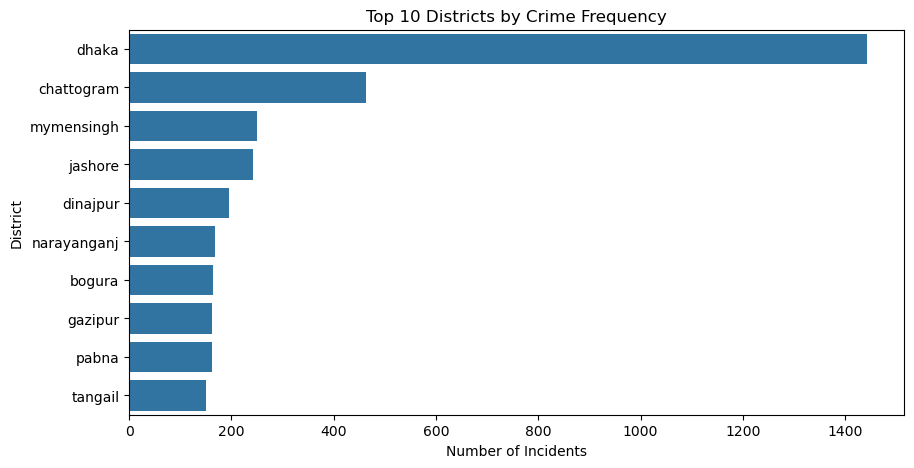

In [417]:
# Explore the data

plt.figure(figsize=(10,5))

top_districts = df["incident_district"].value_counts().head(10)

sns.barplot(
    x=top_districts.values,
    y=top_districts.index
)

plt.title("Top 10 Districts by Crime Frequency")
plt.xlabel("Number of Incidents")
plt.ylabel("District")
plt.show()

**Distribusi kejadian kriminal menunjukkan konsentrasi yang tinggi pada beberapa distrik utama, terutama Dhaka, diikuti oleh Chattogram dan Mymensingh. Pola ini mengindikasikan bahwa wilayah dengan kepadatan penduduk tinggi, urbanisasi kuat, dan aktivitas ekonomi intensif cenderung memiliki tingkat kriminalitas yang lebih tinggi. Sementara itu, distrik-distrik dengan populasi lebih kecil menunjukkan frekuensi kejadian yang lebih rendah. Temuan ini menegaskan bahwa faktor spasial dan karakteristik wilayah memiliki peran signifikan dalam pola kriminalitas, sehingga pendekatan keamanan berbasis wilayah (area-based policing) menjadi relevan untuk perencanaan strategi kepolisian.**

**Incident Vision**

In [418]:
df['incident_division'].describe()

count      6574
unique      192
top       dhaka
freq       1806
Name: incident_division, dtype: object

In [419]:
df['incident_division'].value_counts()

incident_division
dhaka         1806
chattogram     918
rajshahi       700
rangpur        626
khulna         611
              ... 
RAngpuR          1
rAJSHaHi         1
MyMensINgH       1
sylheT           1
cHATtOGRam       1
Name: count, Length: 192, dtype: int64

In [420]:
df['incident_division'].isna().sum()

0

**Variabel incident_division mengalami inkonsistensi semantik dan struktural yang signifikan. Meskipun tidak ditemukan missing value, jumlah kategori unik mencapai 192, yang secara logis tidak sesuai dengan jumlah divisi administratif Bangladesh yang sebenarnya. Inkonsistensi ini disebabkan oleh perbedaan kapitalisasi huruf, spasi berlebih, variasi penulisan, serta format string yang tidak konsisten (misalnya "dhaka", "Dhaka", "DHAKA", " dHaKa "). Permasalahan ini menyebabkan redundansi kategori dan distorsi representasi data spasial, sehingga diperlukan proses normalisasi dan standardisasi teks sebelum variabel ini dapat digunakan dalam analisis lebih lanjut.**

In [421]:
# 1. Normalisasi format teks
df["incident_division"] = df["incident_division"].str.lower()
df["incident_division"] = df["incident_division"].str.strip()

# 2. Mapping ke nama standar
division_mapping = {
    "dhaka": "dhaka",
    "gazipur": "gazipur",
    "chattogram": "chattogram",
    "rajshahi": "rajshahi",
    "khulna": "khulna",
    "barisal": "barisal",
    "sylhet": "sylhet",
    "rangpur": "rangpur",
    "mymensingh": "mymensingh"
}

df["incident_division"] = df["incident_division"].map(division_mapping)

In [422]:
df['incident_division'].value_counts()

incident_division
dhaka         2046
chattogram    1061
rajshahi       782
rangpur        703
khulna         697
mymensingh     449
sylhet         424
barisal        408
gazipur          4
Name: count, dtype: int64

**Precip**

In [423]:
df['precip'].describe()

count    6574.000000
mean        6.187998
std        11.989998
min         0.000000
25%         0.000000
50%         0.800000
75%         7.500000
max       204.600000
Name: precip, dtype: float64

In [424]:
df['precip'].value_counts()

precip
0.0     2616
0.1      178
0.2      126
0.3       91
0.8       84
        ... 
71.9       1
40.3       1
42.1       1
34.6       1
74.5       1
Name: count, Length: 475, dtype: int64

In [425]:
df['precip'].isna().sum()

0

**Variabel precip merupakan variabel numerik kontinu yang merepresentasikan tingkat curah hujan (mm) pada hari terjadinya insiden. Data menunjukkan rentang nilai dari 0 hingga lebih dari 200 mm, dengan median yang rendah dan distribusi yang sangat tidak simetris (right-skewed). Mayoritas nilai berada pada curah hujan rendah (termasuk 0 mm), yang menunjukkan banyak kejadian terjadi pada hari tanpa hujan. Tidak ditemukan missing value pada variabel ini, sehingga secara kelengkapan data precip sudah lengkap. Namun, secara distribusi statistik terdapat nilai ekstrem (curah hujan sangat tinggi) yang berpotensi menjadi outlier alami akibat kondisi cuaca ekstrem.**

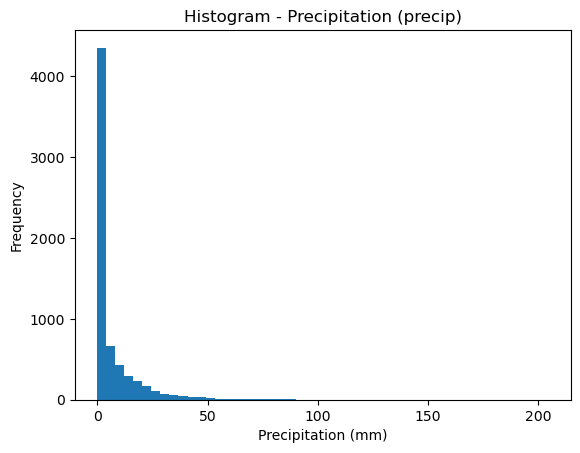

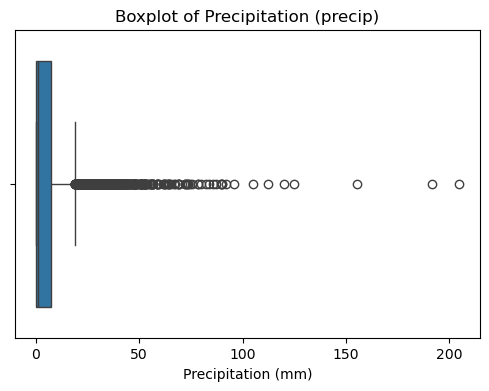

In [426]:
# Explore the data
# =========================
# Histogram - precip
# =========================
plt.figure()
plt.hist(df["precip"], bins=50)
plt.title("Histogram - Precipitation (precip)")
plt.xlabel("Precipitation (mm)")
plt.ylabel("Frequency")
plt.show()

# =========================
# Boxplot - precip
# =========================
plt.figure(figsize=(6,4))
sns.boxplot(x=df["precip"])
plt.title("Boxplot of Precipitation (precip)")
plt.xlabel("Precipitation (mm)")
plt.show()

**Distribusi variabel precip menunjukkan pola sangat skewed ke kanan, dengan mayoritas kejadian terjadi pada kondisi tanpa hujan atau hujan ringan. Outlier yang muncul pada nilai curah hujan tinggi merepresentasikan fenomena cuaca ekstrem yang bersifat alami dan valid secara fisik, bukan kesalahan input data. Oleh karena itu, outlier pada variabel ini dikategorikan sebagai natural outliers dan tidak perlu dilakukan penghapusan atau imputasi, karena tetap mengandung informasi penting terkait kondisi lingkungan terhadap pola kriminalitas.**

**Visibility**

In [427]:
df['visibility'].describe()

count    6574.000000
mean        9.488287
std         0.922742
min         4.000000
25%         9.000000
50%        10.000000
75%        10.000000
max        10.000000
Name: visibility, dtype: float64

In [428]:
df['visibility'].value_counts()

visibility
10    4535
9     1179
8      541
7      211
6       73
5       32
4        3
Name: count, dtype: int64

In [429]:
df['visibility'].isna().sum()

0

**Distribusi variabel visibility menunjukkan konsentrasi yang sangat tinggi pada nilai 9–10 km, dengan median dan kuartil atas berada pada nilai maksimum (10 km), yang mengindikasikan bahwa sebagian besar kejadian kriminal terjadi pada kondisi jarak pandang yang baik. Tidak ditemukan missing value maupun nilai tidak logis, serta tidak terlihat outlier ekstrem yang bersifat anomali. Pola ini menunjukkan bahwa visibilitas rendah bukan faktor dominan dalam terjadinya kriminalitas, sehingga variabel visibility lebih berperan sebagai faktor lingkungan pendukung (contextual variable) daripada faktor utama dalam pembentukan pola kriminalitas.**

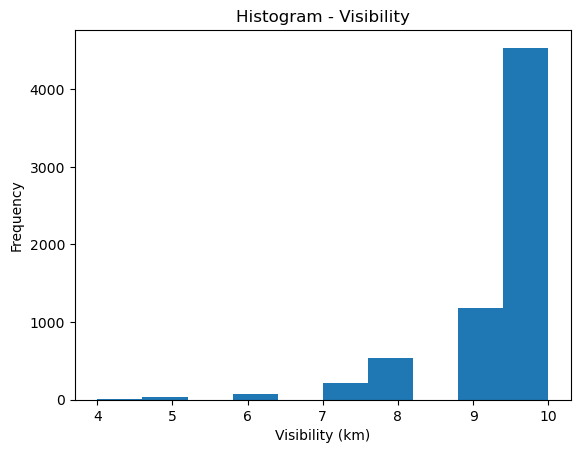

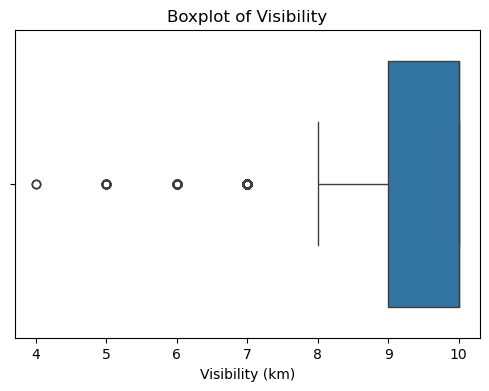

In [430]:
# =========================
# Histogram - visibility
# =========================
plt.figure()
plt.hist(df["visibility"], bins=10)
plt.title("Histogram - Visibility")
plt.xlabel("Visibility (km)")
plt.ylabel("Frequency")
plt.show()

# =========================
# Boxplot - visibility
# =========================
plt.figure(figsize=(6,4))
sns.boxplot(x=df["visibility"])
plt.title("Boxplot of Visibility")
plt.xlabel("Visibility (km)")
plt.show()

**Distribusi variabel visibility menunjukkan dominasi nilai tinggi (9–10 km), yang menandakan bahwa sebagian besar kejadian kriminal terjadi pada kondisi jarak pandang yang baik. Boxplot memperlihatkan beberapa titik ekstrem pada visibilitas rendah (4–6 km), namun nilai tersebut masih berada dalam rentang fisik yang wajar dan merepresentasikan kondisi cuaca alami seperti kabut atau hujan lebat. Outlier yang muncul dikategorikan sebagai natural outliers dan tidak memerlukan penanganan khusus, karena tidak mencerminkan kesalahan data. Secara analitis, variabel visibility lebih berperan sebagai faktor lingkungan pendukung (contextual factor) dibandingkan faktor utama dalam pembentukan pola kriminalitas.**

**heat index**

In [431]:
df['heatindex'].describe()

count    6574.000000
mean       31.597657
std         5.502593
min        15.000000
25%        27.000000
50%        33.000000
75%        36.000000
max        43.000000
Name: heatindex, dtype: float64

In [432]:
df['heatindex'].value_counts()

heatindex
36    595
35    573
37    532
38    412
34    407
33    366
32    341
25    328
24    300
26    282
29    277
28    272
31    270
39    269
27    265
30    261
23    217
22    163
40    134
21    118
20     74
41     52
19     23
42     22
18      9
17      5
43      4
15      2
16      1
Name: count, dtype: int64

In [433]:
df['heatindex'].isna().sum()

0

**tidak ada missing value dan inconsistent data**

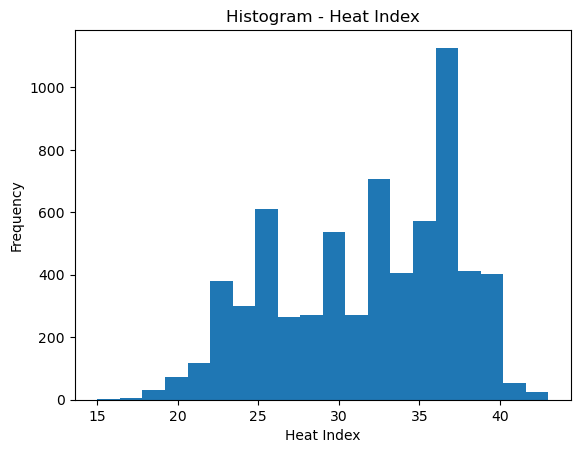

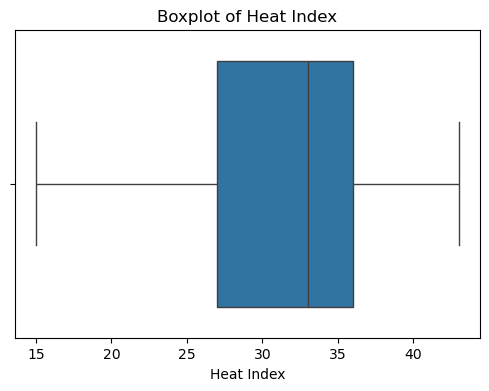

In [434]:
# =========================
# Histogram - heatindex
# =========================
plt.figure()
plt.hist(df["heatindex"], bins=20)
plt.title("Histogram - Heat Index")
plt.xlabel("Heat Index")
plt.ylabel("Frequency")
plt.show()

# =========================
# Boxplot - heatindex
# =========================
plt.figure(figsize=(6,4))
sns.boxplot(x=df["heatindex"])
plt.title("Boxplot of Heat Index")
plt.xlabel("Heat Index")
plt.show()


**Distribusi variabel heatindex menunjukkan sebaran yang relatif normal dengan konsentrasi nilai pada rentang 30–36, yang mencerminkan kondisi cuaca panas yang dominan di Bangladesh. Boxplot memperlihatkan adanya nilai ekstrem pada sisi rendah dan tinggi, namun nilai tersebut masih berada dalam rentang fisik yang wajar secara klimatologis dan tidak mengindikasikan kesalahan data. Outlier yang muncul dikategorikan sebagai natural outliers dan tidak memerlukan penanganan khusus. Variabel heatindex dengan demikian layak dipertahankan dalam bentuk aslinya sebagai faktor lingkungan yang berpotensi memengaruhi pola aktivitas sosial dan risiko kriminalitas.**

**Season**

In [435]:
df['season'].describe()

count      6574
unique        3
top       rainy
freq       2850
Name: season, dtype: object

In [436]:
df['season'].value_counts()

season
rainy     2850
winter    1939
hot       1785
Name: count, dtype: int64

In [437]:
df['season'].isna().sum()

0

**data aman tidak memiliki missing value dan data yang tidak konsisten**

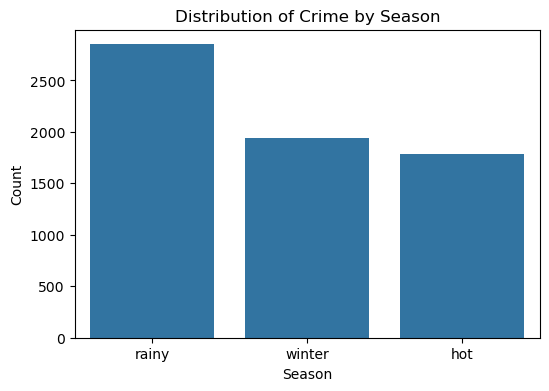

In [438]:
# Explore the data

# =========================
# Visualization - season
# =========================
plt.figure(figsize=(6,4))
sns.countplot(
    x="season",
    data=df,
    order=df["season"].value_counts().index
)

plt.title("Distribution of Crime by Season")
plt.xlabel("Season")
plt.ylabel("Count")
plt.show()

**Distribusi kejadian kriminal berdasarkan variabel season menunjukkan bahwa musim hujan (*rainy*) memiliki jumlah kejadian tertinggi, diikuti oleh musim dingin (*winter*) dan musim panas (*hot*). Pola ini mengindikasikan bahwa kondisi musim dan faktor lingkungan memiliki keterkaitan dengan aktivitas kriminal, kemungkinan melalui pengaruhnya terhadap mobilitas masyarakat, aktivitas ekonomi, serta pola interaksi sosial. Variabel season dengan demikian relevan sebagai faktor kontekstual dalam analisis pola kriminalitas dan pemodelan berbasis lingkungan.**

**Male Population**

In [439]:
df['male_population'].describe()

count    6.574000e+03
mean     8.936342e+05
std      1.605205e+06
min      1.132000e+04
25%      1.319300e+05
50%      1.872290e+05
75%      3.917070e+05
max      4.931802e+06
Name: male_population, dtype: float64

In [440]:
df['male_population'].value_counts()

male_population
4931802    872
1367852    289
738764     245
176023      96
232974      91
          ... 
30516        1
122285       1
80430        1
78175        1
88818        1
Name: count, Length: 455, dtype: int64

In [441]:
df['male_population'].isna().sum()

0

**data aman tidak ada missing value dan inkonsistent data**

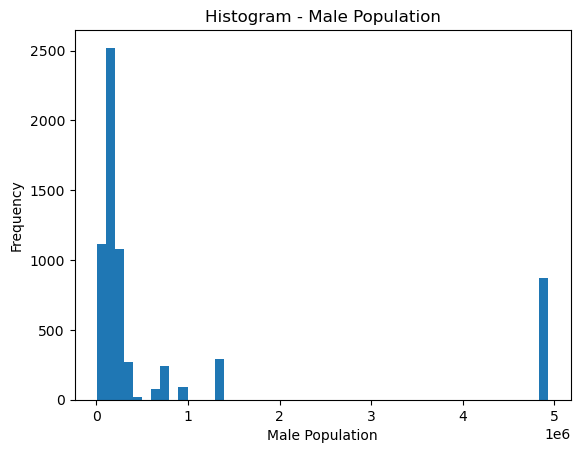

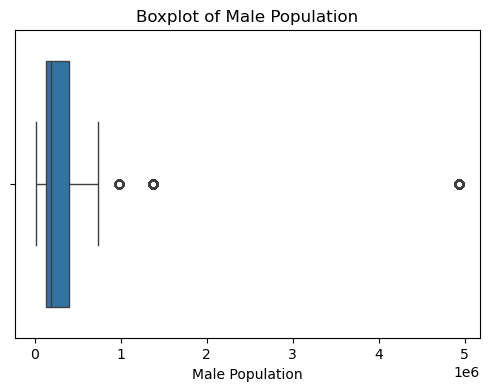

In [442]:
# =========================
# Histogram - male_population
# =========================
plt.figure()
plt.hist(df["male_population"], bins=50)
plt.title("Histogram - Male Population")
plt.xlabel("Male Population")
plt.ylabel("Frequency")
plt.show()

# =========================
# Boxplot - male_population
# =========================
plt.figure(figsize=(6,4))
sns.boxplot(x=df["male_population"])
plt.title("Boxplot of Male Population")
plt.xlabel("Male Population")
plt.show()


**Distribusi variabel male_population menunjukkan sebaran yang sangat tidak simetris (right-skewed), dengan mayoritas wilayah memiliki jumlah populasi laki-laki relatif rendah hingga menengah, serta beberapa wilayah dengan populasi sangat besar. Boxplot memperlihatkan adanya nilai ekstrem pada sisi atas distribusi, yang merepresentasikan wilayah metropolitan atau pusat populasi besar. Outlier yang muncul bersifat natural dan mencerminkan variasi demografis antarwilayah, bukan kesalahan data. Oleh karena itu, tidak diperlukan penghapusan atau imputasi outlier, dan variabel male_population tetap dipertahankan sebagai indikator demografis penting dalam analisis spasial dan klasterisasi wilayah.**

**female Population**

In [443]:
df['female_population'].describe()

count    6.574000e+03
mean     7.544586e+05
std      1.284180e+06
min      1.124700e+04
25%      1.339960e+05
50%      1.870170e+05
75%      3.811572e+05
max      3.974237e+06
Name: female_population, dtype: float64

In [444]:
df['female_population'].value_counts()

female_population
3974237    872
1224587    289
647146     245
167942      96
216782      91
          ... 
29062        1
126066       1
79633        1
78206        1
94163        1
Name: count, Length: 455, dtype: int64

In [445]:
df['female_population'].isna().sum()

0

**Tidak ada missing value**

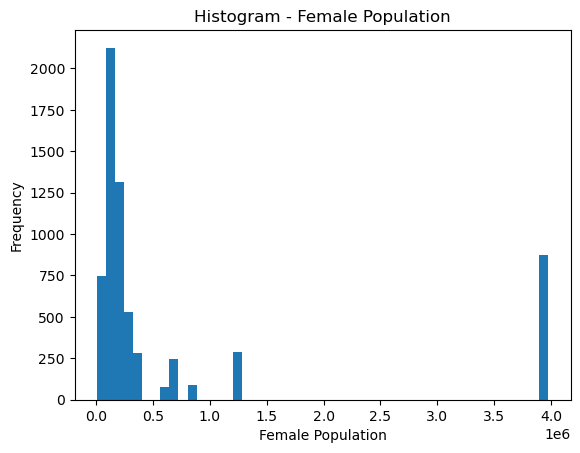

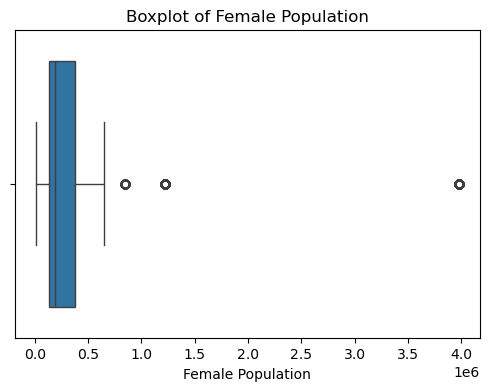

In [446]:
# =========================
# Histogram - female_population
# =========================
plt.figure()
plt.hist(df["female_population"], bins=50)
plt.title("Histogram - Female Population")
plt.xlabel("Female Population")
plt.ylabel("Frequency")
plt.show()

# =========================
# Boxplot - female_population
# =========================
plt.figure(figsize=(6,4))
sns.boxplot(x=df["female_population"])
plt.title("Boxplot of Female Population")
plt.xlabel("Female Population")
plt.show()


**Distribusi variabel female_population menunjukkan pola sebaran yang sangat tidak simetris (right-skewed), dengan mayoritas wilayah memiliki jumlah populasi perempuan relatif rendah hingga menengah, serta beberapa wilayah dengan populasi sangat besar. Boxplot memperlihatkan adanya nilai ekstrem pada sisi atas distribusi, yang merepresentasikan wilayah metropolitan dan pusat kepadatan penduduk. Outlier yang muncul bersifat alami dan mencerminkan perbedaan demografis antarwilayah, bukan kesalahan data. Oleh karena itu, tidak diperlukan penghapusan atau imputasi outlier, dan variabel female_population tetap dipertahankan sebagai indikator demografis penting dalam analisis pola kriminalitas dan klasterisasi wilayah.**

**Total Population**

hasil penjumlahan male population dan female population

In [447]:
# Validasi bahwa total_population = male + female
check = df["male_population"] + df["female_population"] - df["total_population"]

print("Max difference:", check.abs().max())
print("Rows with mismatch:", (check != 0).sum())

Max difference: 10900
Rows with mismatch: 113


**Variabel total_population menunjukkan inkonsistensi struktural terhadap variabel pembentuknya, yaitu male_population dan female_population. Hasil validasi matematis menunjukkan bahwa pada sejumlah observasi, nilai total_population tidak sama dengan hasil penjumlahan populasi laki-laki dan perempuan, yang menandakan adanya pelanggaran integritas data (data integrity violation). Kondisi ini menunjukkan bahwa total_population tidak sepenuhnya dapat dianggap sebagai variabel turunan yang valid secara struktural. Oleh karena itu, diperlukan rekonstruksi variabel total_population untuk menjaga konsistensi demografis dan validitas analisis lanjutan.**

In [448]:
df["total_population"] = df["male_population"] + df["female_population"]

In [449]:
check = df["male_population"] + df["female_population"] - df["total_population"]

print("Max difference:", check.abs().max())
print("Rows with mismatch:", (check != 0).sum())

Max difference: 0
Rows with mismatch: 0


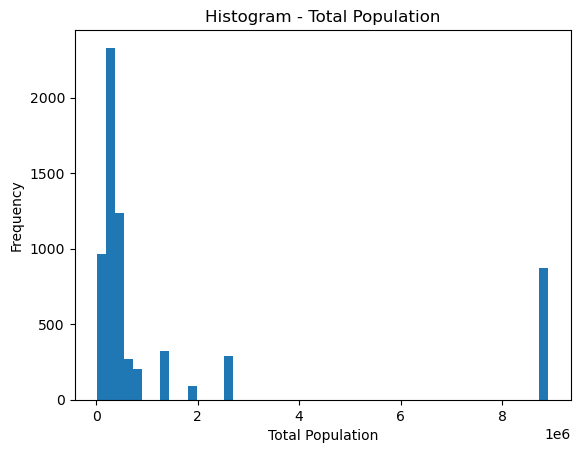

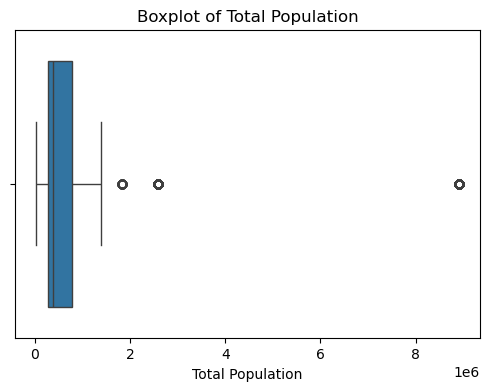

In [450]:
# =========================
# Histogram - total_population
# =========================
plt.figure()
plt.hist(df["total_population"], bins=50)
plt.title("Histogram - Total Population")
plt.xlabel("Total Population")
plt.ylabel("Frequency")
plt.show()

# =========================
# Boxplot - total_population
# =========================
plt.figure(figsize=(6,4))
sns.boxplot(x=df["total_population"])
plt.title("Boxplot of Total Population")
plt.xlabel("Total Population")
plt.show()


**Distribusi variabel total_population menunjukkan pola sebaran yang sangat tidak simetris (right-skewed), dengan mayoritas wilayah memiliki populasi rendah hingga menengah, serta beberapa wilayah dengan populasi sangat besar yang merepresentasikan pusat urban dan wilayah metropolitan. Boxplot memperlihatkan adanya nilai ekstrem pada sisi atas distribusi, yang mencerminkan perbedaan skala demografis antarwilayah dan bukan kesalahan data. Outlier yang muncul dikategorikan sebagai natural demographic outliers dan tidak memerlukan penghapusan atau imputasi. Variabel total_population tetap relevan sebagai indikator utama kepadatan dan skala wilayah dalam analisis spasial dan klasterisasi wilayah berbasis risiko kriminalitas.**
**

**Gender Ration**

In [451]:
df['gender_ration'].describe()

count    6574.000000
mean      104.429723
std        10.387173
min        84.000000
25%        98.000000
50%       101.000000
75%       109.000000
max       203.000000
Name: gender_ration, dtype: float64

In [452]:
df['gender_ration'].value_counts()

gender_ration
125    872
99     610
101    579
100    551
98     432
96     379
102    345
110    316
97     309
114    260
95     247
105    225
109    185
104    176
108    130
94     123
103    109
107    106
93      98
116     90
92      90
91      66
90      57
106     51
89      42
113     28
111     20
117     17
86      13
85      13
84      13
88      11
203      7
87       4
Name: count, dtype: int64

In [453]:
df['gender_ration'].isna().sum()

0

**Data aman tidak ad missing value dan inkonsistent data**

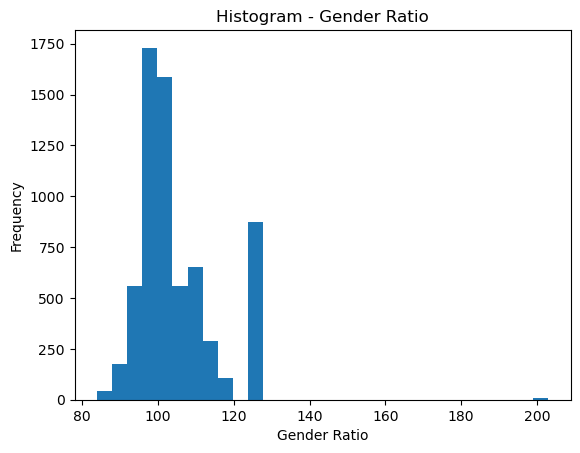

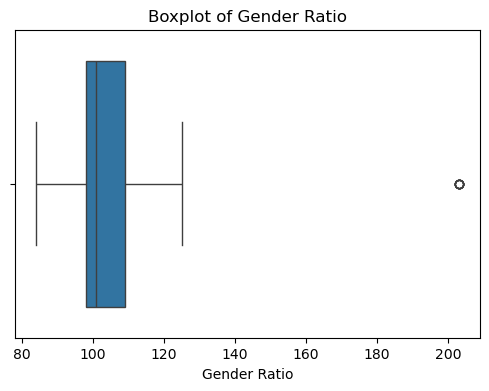

In [454]:
# =========================
# Histogram - gender_ration
# =========================
plt.figure()
plt.hist(df["gender_ration"], bins=30)
plt.title("Histogram - Gender Ratio")
plt.xlabel("Gender Ratio")
plt.ylabel("Frequency")
plt.show()

# =========================
# Boxplot - gender_ration
# =========================
plt.figure(figsize=(6,4))
sns.boxplot(x=df["gender_ration"])
plt.title("Boxplot of Gender Ratio")
plt.xlabel("Gender Ratio")
plt.show()


Distribusi variabel gender_ration menunjukkan konsentrasi nilai di sekitar rentang 95–110, yang mencerminkan keseimbangan relatif antara populasi laki-laki dan perempuan di sebagian besar wilayah. Boxplot memperlihatkan adanya nilai ekstrem pada sisi bawah dan atas distribusi, namun nilai tersebut masih berada dalam rentang demografis yang wajar dan tidak mengindikasikan kesalahan data. Outlier yang muncul merepresentasikan variasi alami struktur populasi antarwilayah dan dikategorikan sebagai natural demographic outliers, sehingga tidak memerlukan penghapusan atau imputasi. Variabel gender_ration tetap relevan sebagai indikator struktur demografis dalam analisis spasial dan klasterisasi wilayah.


**Average HouseHold Size**

In [455]:
df['average_household_size'].describe()

count    6574.000000
mean        4.965023
std         1.422850
min         3.580000
25%         4.110000
50%         4.440000
75%         5.100000
max         8.420000
Name: average_household_size, dtype: float64

In [456]:
df['average_household_size'].value_counts()

average_household_size
8.42    872
4.60    313
3.77    269
4.10    244
4.30    184
       ... 
4.96      2
5.33      1
5.60      1
4.18      1
4.76      1
Name: count, Length: 164, dtype: int64

In [457]:
df['average_household_size'].isna().sum()

0

**Data aman tidak ada missing value dan inconsistemt data**

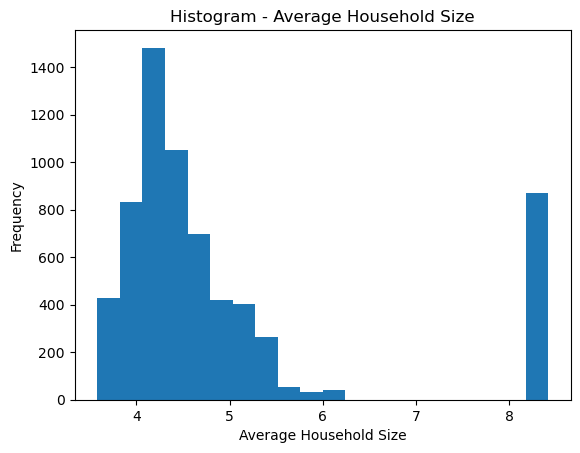

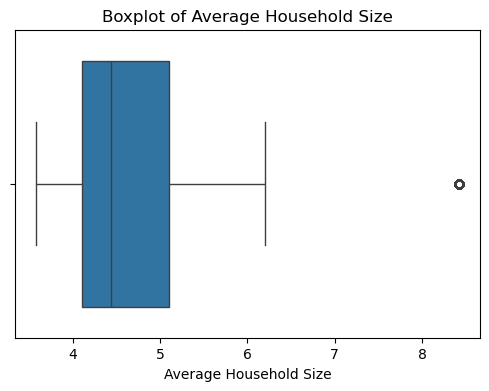

In [458]:
# =========================
# Histogram - average_household_size
# =========================
plt.figure()
plt.hist(df["average_household_size"], bins=20)
plt.title("Histogram - Average Household Size")
plt.xlabel("Average Household Size")
plt.ylabel("Frequency")
plt.show()

# =========================
# Boxplot - average_household_size
# =========================
plt.figure(figsize=(6,4))
sns.boxplot(x=df["average_household_size"])
plt.title("Boxplot of Average Household Size")
plt.xlabel("Average Household Size")
plt.show()


**Distribusi variabel average_household_size menunjukkan sebaran yang relatif sempit dengan konsentrasi nilai pada rentang 4–5 orang per rumah tangga, yang mencerminkan pola struktur keluarga yang relatif homogen antarwilayah. Boxplot tidak menunjukkan outlier ekstrem yang bersifat anomali, dan seluruh nilai berada dalam rentang yang logis secara demografis. Hal ini menunjukkan bahwa variabel average_household_size memiliki stabilitas tinggi dan kualitas data yang baik, sehingga tidak memerlukan proses cleaning atau penanganan outlier, serta layak digunakan sebagai indikator sosial-demografis dalam analisis spasial dan klasterisasi wilayah.**

**Densisty Per Kmsq**

In [459]:
df['density_per_kmsq'].describe()

count    6.574000e+03
mean     1.891212e+52
std      1.354499e+54
min      5.615431e-61
25%      9.100000e+02
50%      1.239000e+03
75%      4.318000e+03
max      1.090315e+56
Name: density_per_kmsq, dtype: float64

In [460]:
df['density_per_kmsq'].value_counts()

density_per_kmsq
3.055100e+04    853
2.019000e+04    283
4.948000e+03    242
2.747000e+03     95
4.318000e+03     90
               ... 
5.943274e+12      1
5.530000e+02      1
2.187577e+46      1
3.253817e-27      1
6.822335e+28      1
Name: count, Length: 515, dtype: int64

In [461]:
df['density_per_kmsq'].isna().sum()

0

**tidak ada missing value dan inconsistent data**

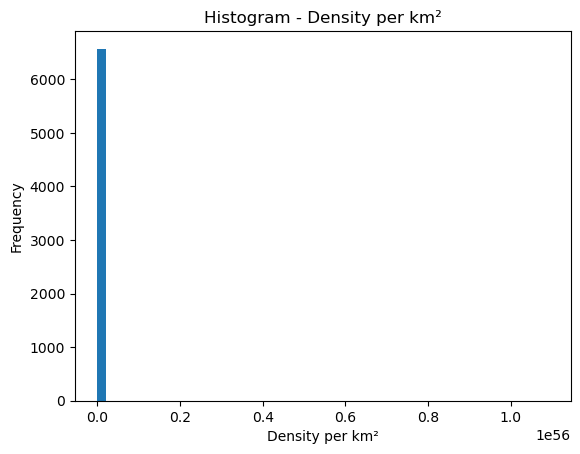

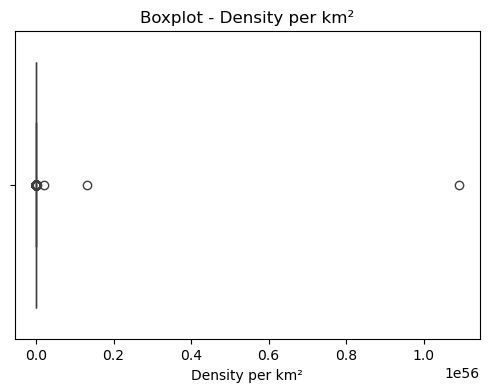

In [462]:
# =========================
# Histogram
# =========================
plt.figure()
plt.hist(df["density_per_kmsq"], bins=50)
plt.title("Histogram - Density per km²")
plt.xlabel("Density per km²")
plt.ylabel("Frequency")
plt.show()

# =========================
# Boxplot
# =========================
plt.figure(figsize=(6,4))
sns.boxplot(x=df["density_per_kmsq"])
plt.title("Boxplot - Density per km²")
plt.xlabel("Density per km²")
plt.show()


**Data Quality Issue pada Variabel density_per_kmsq**

Variabel density_per_kmsq menunjukkan banyak nilai yang tidak masuk akal secara statistik dan logis, seperti angka yang sangat besar/kecil dalam notasi ilmiah (misalnya 1e+55, 1e-48, 3e+40) yang tidak mungkin merepresentasikan kepadatan penduduk riil per km². Pola ini mengindikasikan adanya kesalahan struktural dalam proses perhitungan, input data, atau proses integrasi dataset.

Selain itu, kepadatan penduduk secara konseptual merupakan variabel turunan (*derived variable*) yang seharusnya dihitung dari total_population / luas_wilayah_km2, sementara dataset tidak menyediakan variabel luas wilayah. Akibatnya, nilai density_per_kmsq tidak dapat diverifikasi secara ilmiah dan validitasnya tidak dapat dipastikan.

Sebagai solusi data quality, variabel density_per_kmsq di-drop dari dataset karena:
1. Mengandung anomali numerik ekstrem yang tidak realistis  
2. Tidak dapat diverifikasi secara metodologis  
3. Berpotensi merusak stabilitas EDA, clustering, dan modeling  

Penghapusan variabel ini bertujuan menjaga integritas analisis dan kualitas hasil pemodelan.

In [463]:
# Drop invalid derived feature
df.drop(columns=["density_per_kmsq"], inplace=True)

**literacy Rate**

In [464]:
df['literacy_rate'].describe()

count    6246.000000
mean       55.742683
std        12.082504
min        26.700000
25%        46.600000
50%        53.900000
75%        67.200000
max        74.600000
Name: literacy_rate, dtype: float64

In [465]:
df['literacy_rate'].value_counts()

literacy_rate
74.6    834
68.8    281
68.0    233
60.6    100
61.3     91
       ... 
67.8      1
55.3      1
40.7      1
50.6      1
41.6      1
Name: count, Length: 264, dtype: int64

In [466]:
df['literacy_rate'].isna().sum()

328

**Variabel literacy_rate merepresentasikan persentase penduduk melek huruf di setiap wilayah. Secara statistik, nilai berada pada rentang **26.7% – 74.6%** dengan median sekitar **53.9%**, yang masih masuk akal secara sosial-demografis dan tidak menunjukkan anomali nilai ekstrem yang tidak realistis. Distribusi data relatif wajar dan merepresentasikan variasi tingkat literasi antar wilayah di Bangladesh.**

**Namun, terdapat **328 missing value (~5%)**, sehingga diperlukan penanganan sebelum analisis lanjutan. Karena variabel ini bersifat numerik kontinu dan tidak memiliki outlier ekstrem yang tidak wajar, maka **missing value diimputasi menggunakan nilai mean** untuk menjaga stabilitas distribusi data dan menghindari bias struktural pada clustering dan modeling.**

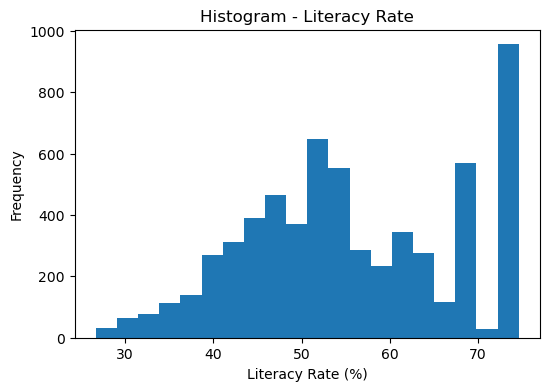

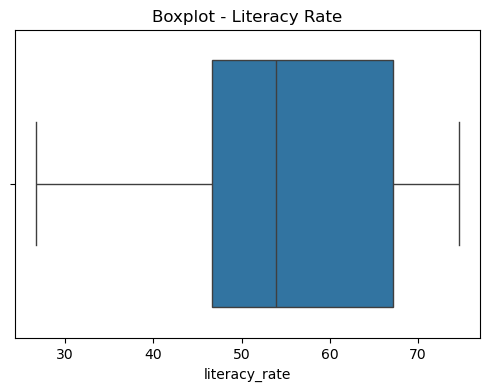

In [467]:
# Histogram literacy_rate
plt.figure(figsize=(6,4))
plt.hist(df['literacy_rate'].dropna(), bins=20)
plt.title("Histogram - Literacy Rate")
plt.xlabel("Literacy Rate (%)")
plt.ylabel("Frequency")
plt.show()

# Boxplot literacy_rate
plt.figure(figsize=(6,4))
sns.boxplot(x=df['literacy_rate'])
plt.title("Boxplot - Literacy Rate")
plt.show()

**Distribusi literacy_rate terlihat relatif **normal dan seimbang**, dengan konsentrasi nilai utama pada rentang **40%–70%**. Boxplot tidak menunjukkan outlier ekstrem yang tidak wajar, serta sebaran data masih berada dalam batas logis secara sosial-demografis. Hal ini menunjukkan bahwa data bersifat stabil dan representatif.Karena distribusi relatif simetris dan tidak skew ekstrem, maka **missing value aman diimputasi menggunakan nilai mean**, tanpa berisiko merusak pola distribusi data maupun struktur analisis.**

In [468]:
df['literacy_rate'] = df['literacy_rate'].fillna(df['literacy_rate'].mean())

In [469]:
df['literacy_rate'].isna().sum()

0

**Religius Institution**

In [470]:
df['religious_institution'].describe()

count    6574.00000
mean     1232.03164
std      1245.17044
min         0.00000
25%       519.00000
50%       818.00000
75%      1125.00000
max      4289.00000
Name: religious_institution, dtype: float64

In [471]:
df['religious_institution'].value_counts()

religious_institution
4289    872
995     289
1118    245
472     101
508      96
       ... 
943       1
327       1
48        1
434       1
295       1
Name: count, Length: 378, dtype: int64

In [472]:
df['religious_institution'].isna().sum()

0

**data tidak ada missing value dan inconsistent data**

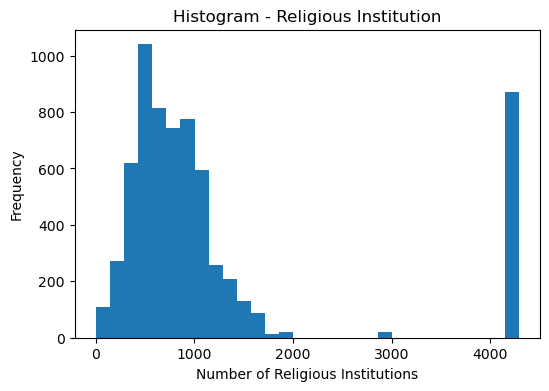

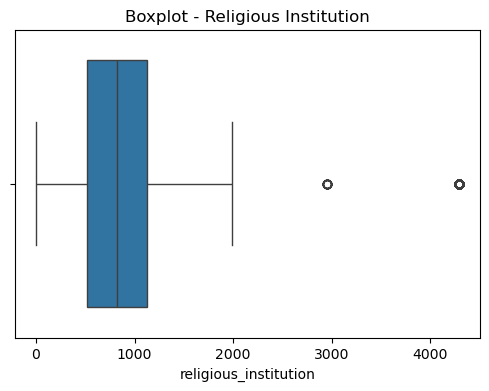

In [473]:
# Histogram religious_institution
plt.figure(figsize=(6,4))
plt.hist(df['religious_institution'], bins=30)
plt.title("Histogram - Religious Institution")
plt.xlabel("Number of Religious Institutions")
plt.ylabel("Frequency")
plt.show()

# Boxplot religious_institution
plt.figure(figsize=(6,4))
sns.boxplot(x=df['religious_institution'])
plt.title("Boxplot - Religious Institution")
plt.show()


**Distribusi religious_institution menunjukkan pola **right-skewed** (condong ke kanan), dengan mayoritas wilayah berada pada kisaran jumlah moderat, namun terdapat beberapa wilayah dengan jumlah institusi keagamaan yang sangat tinggi (outlier ekstrem). Outlier ini **masih masuk akal secara konteks geografis dan demografis** (misalnya wilayah urban padat seperti kota besar), sehingga tidak dikategorikan sebagai error data. Oleh karena itu, outlier tidak perlu dihapus**

**Playground**

In [474]:
df['playground'].describe()

count    6574.000000
mean       42.504411
std        44.857967
min         0.000000
25%         5.000000
50%        25.000000
75%        78.000000
max       253.000000
Name: playground, dtype: float64

In [475]:
df['playground'].value_counts()

playground
99     872
0      621
1      487
59     320
78     252
      ... 
192      3
63       2
96       1
84       1
107      1
Name: count, Length: 106, dtype: int64

In [476]:
df['playground'].isna().sum()

0

**Tidak ada missing value dan inconsistent data**

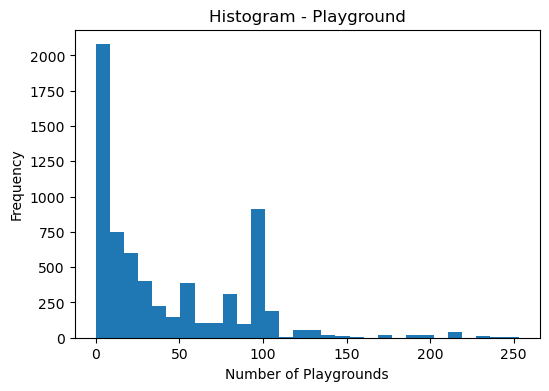

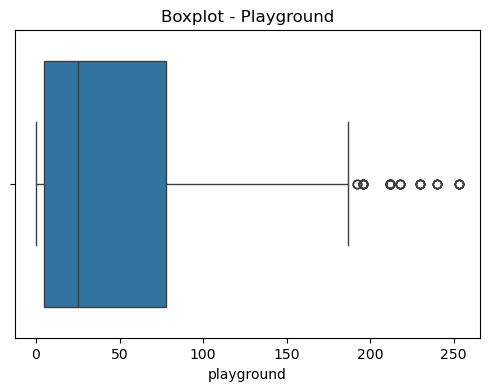

In [477]:
# Histogram playground
plt.figure(figsize=(6,4))
plt.hist(df['playground'], bins=30)
plt.title("Histogram - Playground")
plt.xlabel("Number of Playgrounds")
plt.ylabel("Frequency")
plt.show()

# Boxplot playground
plt.figure(figsize=(6,4))
sns.boxplot(x=df['playground'])
plt.title("Boxplot - Playground")
plt.show()


**Distribusi playground menunjukkan pola **right-skewed**, dengan mayoritas wilayah memiliki jumlah playground yang rendah hingga menengah, serta beberapa wilayah dengan jumlah playground sangat tinggi sebagai outlier. Outlier ini masih **logis secara konteks wilayah urban dan fasilitas publik**, sehingga tidak dikategorikan sebagai error data. Variabel ini tidak memiliki missing value maupun inkonsistensi data, sehingga tidak memerlukan cleaning struktural**


**Park**

In [478]:
df['park'].describe()

count    6574.000000
mean        3.863706
std         5.883186
min         0.000000
25%         0.000000
50%         1.000000
75%         3.000000
max        17.000000
Name: park, dtype: float64

In [479]:
df['park'].value_counts()

park
0     2537
1     1169
17     872
2      683
3      567
11     289
4      181
5       96
15      89
6       53
8       38
Name: count, dtype: int64

In [480]:
df['park'].isna().sum()

0

**Tidak ada missing value dan inconsistent data**

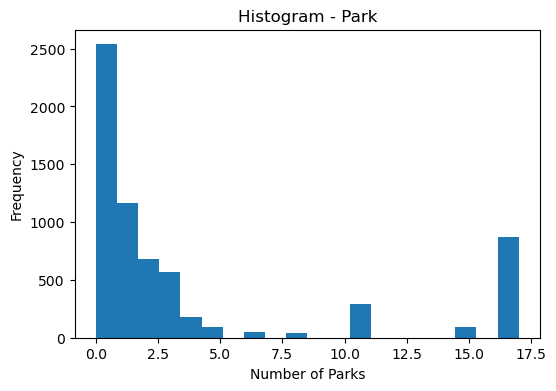

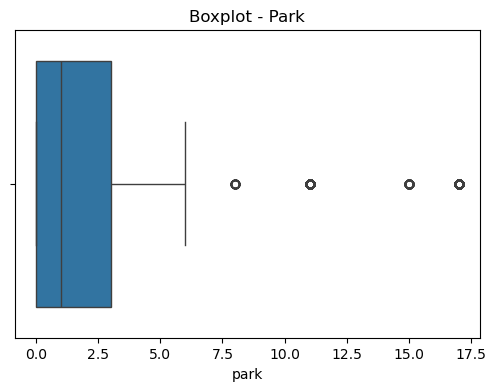

In [481]:
# Histogram park
plt.figure(figsize=(6,4))
plt.hist(df['park'], bins=20)
plt.title("Histogram - Park")
plt.xlabel("Number of Parks")
plt.ylabel("Frequency")
plt.show()

# Boxplot park
plt.figure(figsize=(6,4))
sns.boxplot(x=df['park'])
plt.title("Boxplot - Park")
plt.show()

**Distribusi park sangat **right-skewed**, di mana mayoritas wilayah memiliki jumlah taman yang sangat sedikit (0–2 taman), sementara hanya sebagian kecil wilayah yang memiliki jumlah taman yang tinggi sebagai outlier. Outlier tersebut masih **masuk akal secara konteks wilayah urban dan fasilitas publik**, sehingga tidak dikategorikan sebagai kesalahan data. Oleh karena itu, outlier tidak perlu dihapus**.


**Police Station**

In [482]:
df['police_station'].describe()

count    6574.000000
mean       11.762093
std        19.604510
min        -1.000000
25%         2.000000
50%         3.000000
75%         6.000000
max        74.000000
Name: police_station, dtype: float64

In [483]:
df['police_station'].value_counts()

police_station
 2     1577
 1     1263
 60     871
 3      759
 4      551
 5      425
 6      424
 26     289
 7      169
 11      82
 8       38
 21      36
 0       28
 13      27
 10      22
 12      10
 74       2
-1        1
Name: count, dtype: int64

In [484]:
df['police_station'].isna().sum()

0

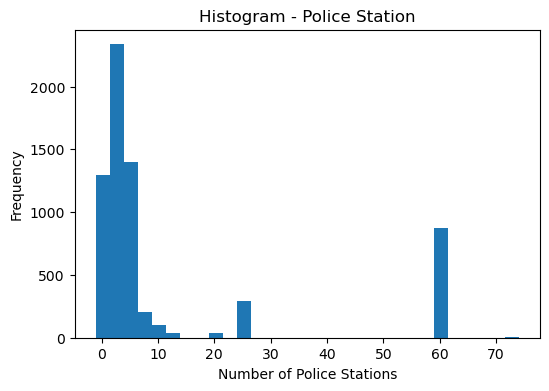

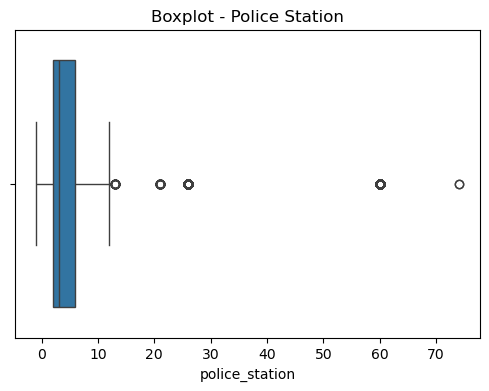

In [485]:
# Histogram police_station
plt.figure(figsize=(6,4))
plt.hist(df['police_station'], bins=30)
plt.title("Histogram - Police Station")
plt.xlabel("Number of Police Stations")
plt.ylabel("Frequency")
plt.show()

# Boxplot police_station
plt.figure(figsize=(6,4))
sns.boxplot(x=df['police_station'])
plt.title("Boxplot - Police Station")
plt.show()

**Distribusi police_station menunjukkan pola **right-skewed**, dengan mayoritas wilayah memiliki jumlah kantor polisi rendah (0–6 unit), serta beberapa wilayah dengan jumlah sangat tinggi sebagai outlier yang masih logis secara konteks wilayah urban.**

Namun, ditemukan **anomali nilai -1**, yang secara logika **tidak valid** karena jumlah kantor polisi tidak mungkin bernilai negatif. Nilai ini menunjukkan adanya **kesalahan input data (data entry error)** atau kesalahan integrasi data.

In [486]:
# Ubah -1 menjadi NaN
df['police_station'] = df['police_station'].replace(-1, np.nan)

# Imputasi dengan median (lebih robust untuk data skewed)
df['police_station'] = df['police_station'].fillna(df['police_station'].median())

**School**

In [487]:
df['school'].describe()

count    6574.000000
mean       75.218893
std        71.743767
min         1.000000
25%        30.000000
50%        45.000000
75%        86.000000
max       242.000000
Name: school, dtype: float64

In [488]:
df['school'].value_counts()

school
242    872
42     328
134    289
23     193
56     173
      ... 
3        7
80       7
68       7
6        6
81       3
Name: count, Length: 88, dtype: int64

In [489]:
df['school'].isna().sum()

0

**tidak ada missing value dan inconsistent data**

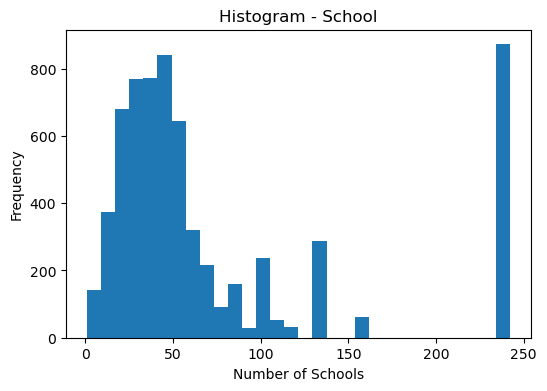

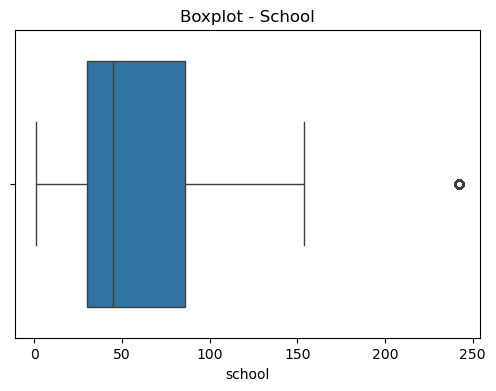

In [490]:
# Histogram school
plt.figure(figsize=(6,4))
plt.hist(df['school'], bins=30)
plt.title("Histogram - School")
plt.xlabel("Number of Schools")
plt.ylabel("Frequency")
plt.show()

# Boxplot school
plt.figure(figsize=(6,4))
sns.boxplot(x=df['school'])
plt.title("Boxplot - School")
plt.show()

**Distribusi school menunjukkan pola **right-skewed**, dengan mayoritas wilayah memiliki jumlah sekolah pada kategori rendah hingga menengah, serta beberapa wilayah dengan jumlah sekolah yang sangat tinggi sebagai outlier. Pola ini masih **logis secara konteks wilayah urban dan kepadatan penduduk**, sehingga tidak dikategorikan sebagai error data. Variabel ini tidak memiliki missing value maupun inkonsistensi data, sehingga tidak memerlukan cleaning struktural**

**Collage**

In [491]:
df['college'].describe()

count    6574.000000
mean       15.479617
std        19.721917
min         0.000000
25%         4.000000
50%         8.000000
75%        15.000000
max        64.000000
Name: college, dtype: float64

In [492]:
df['college'].value_counts()

college
64    872
4     534
3     514
10    512
5     464
8     459
6     422
2     404
1     311
9     297
7     293
21    292
12    266
11    221
16    163
17    110
23     96
0      85
15     84
14     69
13     46
20     24
33     23
22     13
Name: count, dtype: int64

In [493]:
df['college'].isna().sum()

0

**Tidak ada missing value dan inconsistent data**

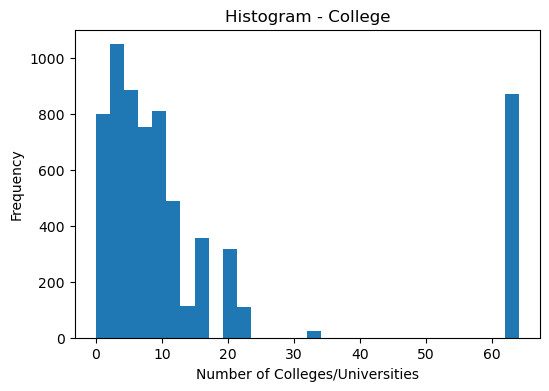

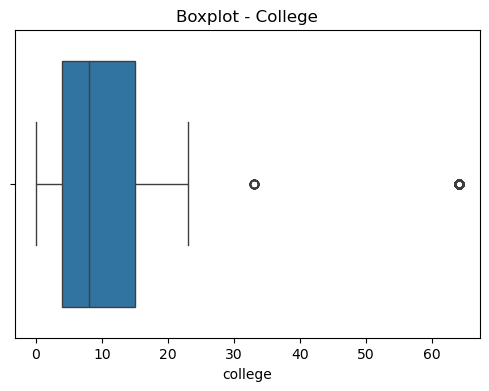

In [494]:
# Histogram college
plt.figure(figsize=(6,4))
plt.hist(df['college'], bins=30)
plt.title("Histogram - College")
plt.xlabel("Number of Colleges/Universities")
plt.ylabel("Frequency")
plt.show()

# Boxplot college
plt.figure(figsize=(6,4))
sns.boxplot(x=df['college'])
plt.title("Boxplot - College")
plt.show()


**Distribusi college menunjukkan pola **right-skewed**, di mana sebagian besar wilayah memiliki jumlah perguruan tinggi yang rendah hingga menengah, serta terdapat beberapa wilayah dengan jumlah yang sangat tinggi sebagai outlier. Pola ini masih **logis secara konteks wilayah urban dan pusat pendidikan**, sehingga tidak dikategorikan sebagai kesalahan data. Variabel ini tidak memiliki missing value maupun inkonsistensi, sehingga tidak memerlukan cleaning struktural**


**Crime - Target Variabel**

In [495]:
df['crime'].describe()

count       6574
unique         6
top       murder
freq        1518
Name: crime, dtype: object

In [496]:
df['crime'].value_counts()

crime
murder       1518
bodyfound    1517
rape         1193
assault      1097
kidnap        651
robbery       598
Name: count, dtype: int64

In [497]:
df['crime'].isna().sum()

0

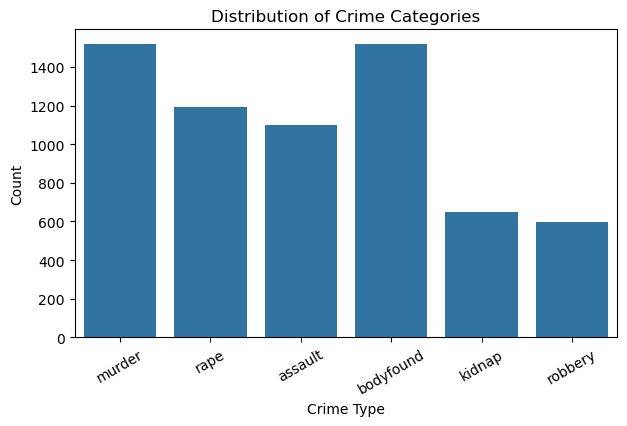

In [498]:
# Bar chart distribusi crime
plt.figure(figsize=(7,4))
sns.countplot(x='crime', data=df)
plt.title("Distribution of Crime Categories")
plt.xlabel("Crime Type")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.show()


**Variabel target crime terdiri dari **6 kategori**: murder, bodyfound, rape, assault, kidnap, dan robbery. Distribusi kelas relatif **cukup seimbang**, dengan sedikit dominasi pada kategori *murder* dan *bodyfound*, namun tidak menunjukkan ketimpangan kelas (class imbalance) yang ekstrem. Tidak terdapat missing value maupun inkonsistensi label.**

**Struktur distribusi ini memungkinkan analisis pola kriminalitas yang representatif serta mendukung proses clustering dan profiling wilayah tanpa bias dominan dari satu kategori kejahatan tertentu.**

**Heat Map**

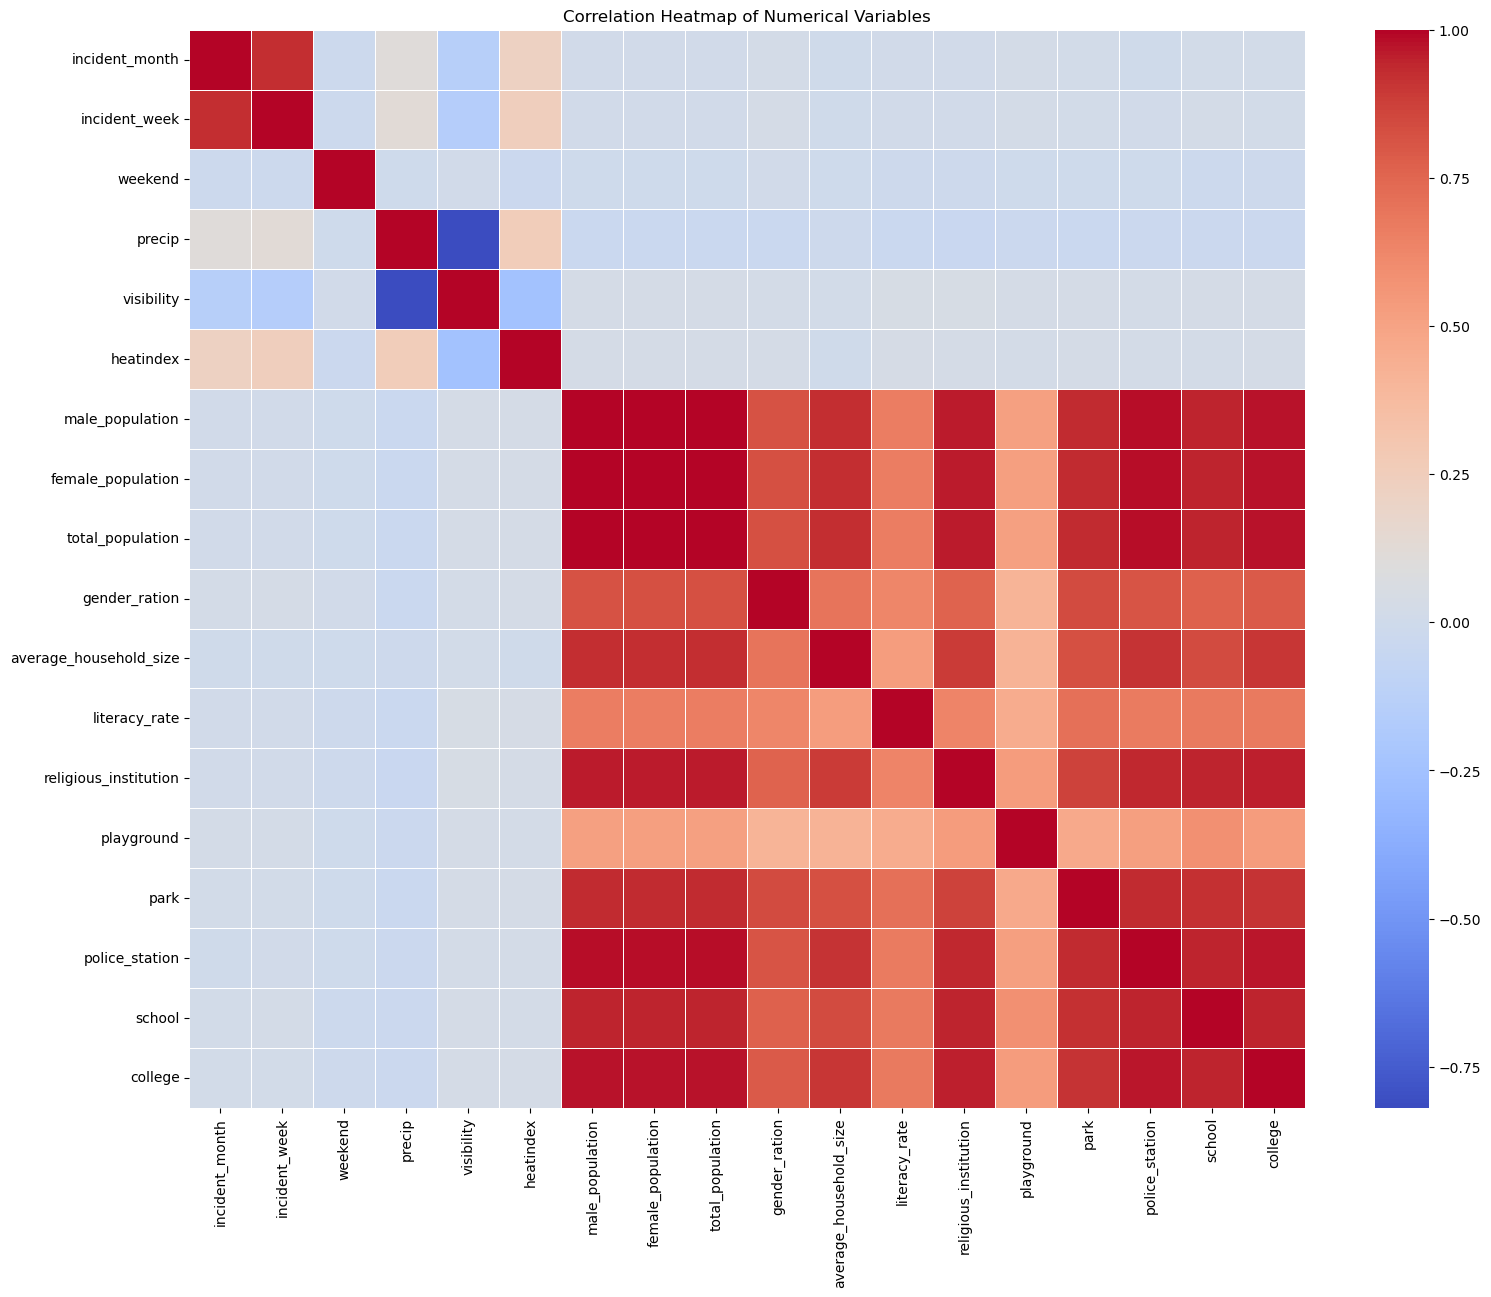

In [499]:
# ambil hanya kolom numerik
numeric_df = df.select_dtypes(include=["int64", "float64"])

# correlation matrix
corr_matrix = numeric_df.corr()

# plot heatmap
plt.figure(figsize=(18,14))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    annot=False,
    linewidths=0.5
)
plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

Heatmap korelasi menunjukkan adanya **kelompok fitur demografis dan infrastruktur** yang memiliki korelasi sangat kuat satu sama lain, terutama antara male_population, female_population, total_population, serta variabel fasilitas publik seperti school, college, police_station, park, playground, dan religious_institution. Pola ini mencerminkan bahwa wilayah dengan populasi besar secara alami memiliki jumlah fasilitas publik yang lebih banyak.

Sebaliknya, variabel temporal dan lingkungan seperti incident_month, incident_week, weekend, precip, visibility, dan heatindex menunjukkan korelasi yang relatif lemah terhadap kelompok variabel demografis, menandakan bahwa faktor waktu dan cuaca membentuk dimensi informasi yang berbeda.

Temuan ini mengindikasikan adanya **multikolinearitas struktural** pada kelompok variabel populasi–infrastruktur, sehingga pada tahap clustering diperlukan **scaling** dan potensi **feature selection/reduction** agar pembentukan klaster tidak didominasi oleh ukuran populasi semata, melainkan mencerminkan karakteristik wilayah secara lebih seimbang.


**incident_weekday vs crime**

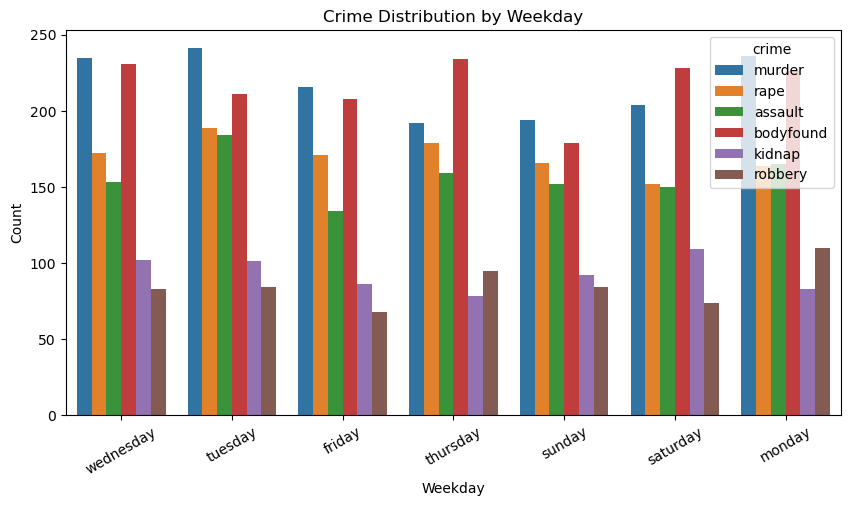

In [500]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='incident_weekday', hue='crime')
plt.title("Crime Distribution by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.show()

**incident_month vs crime**

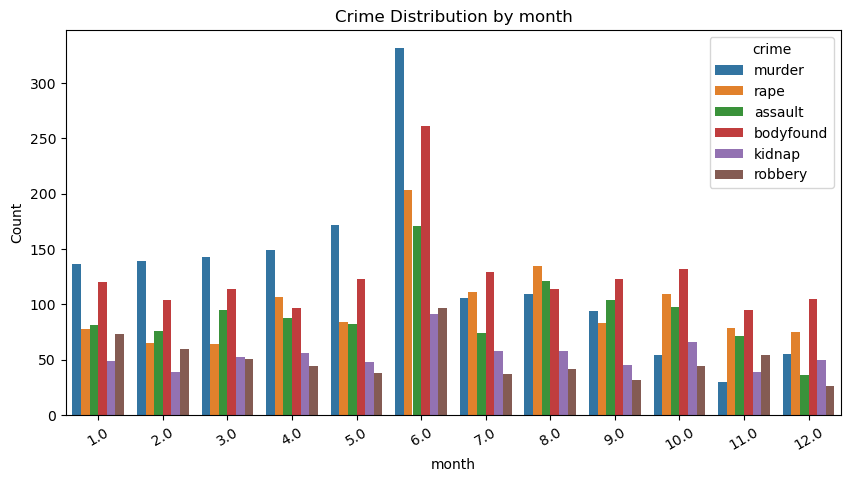

In [501]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='incident_month', hue='crime')
plt.title("Crime Distribution by month")
plt.xlabel("month")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.show()

**Part of the day vs crime**

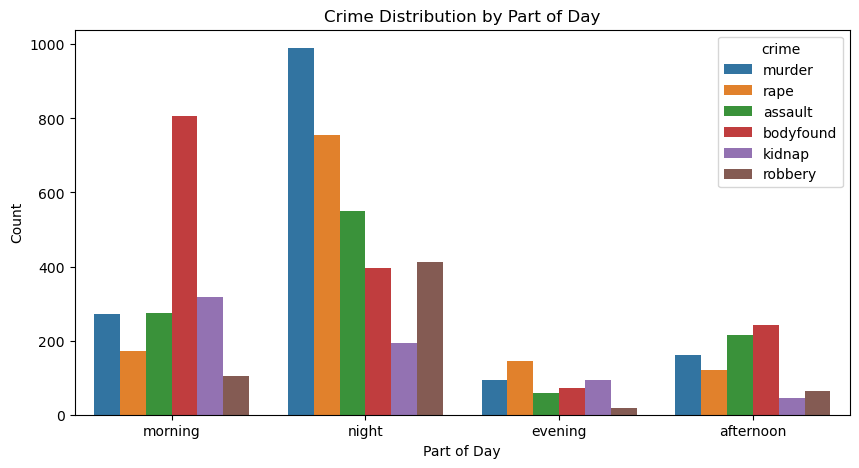

In [502]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='part_of_the_day', hue='crime')
plt.title("Crime Distribution by Part of Day")
plt.xlabel("Part of Day")
plt.ylabel("Count")
plt.show()


**Season vs Crime**

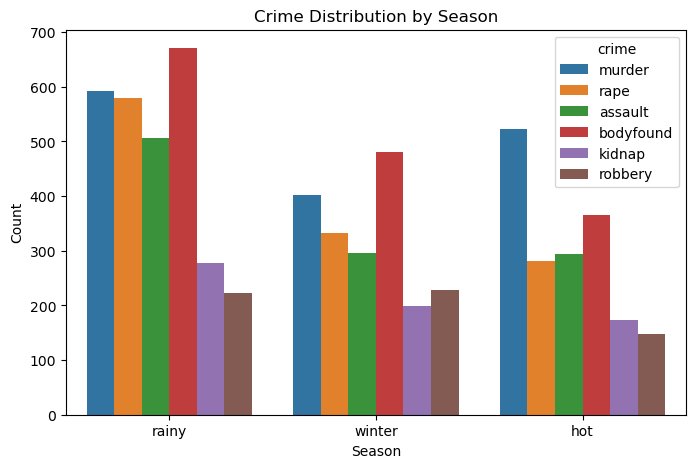

In [503]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='season', hue='crime')
plt.title("Crime Distribution by Season")
plt.xlabel("Season")
plt.ylabel("Count")
plt.show()

**incident_division vs crime (Top 10 division)**

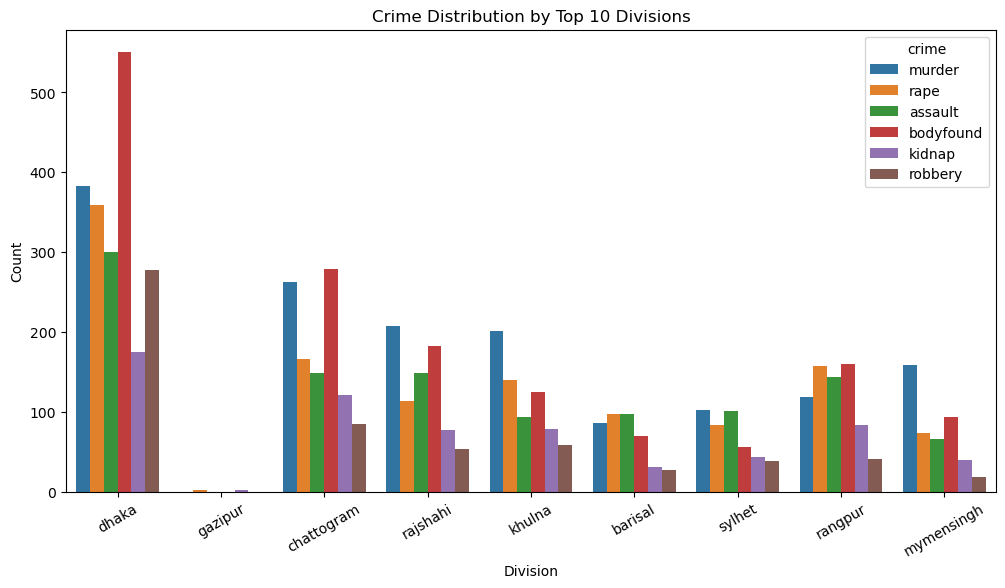

In [504]:
top_div = df['incident_division'].value_counts().head(10).index

plt.figure(figsize=(12,6))
sns.countplot(data=df[df['incident_division'].isin(top_div)],
              x='incident_division', hue='crime')
plt.title("Crime Distribution by Top 10 Divisions")
plt.xlabel("Division")
plt.ylabel("Count")
plt.xticks(rotation=30)
plt.show()


**nsight Visualisasi Variabel Kategorik vs Target (crime)**

**1. Incident Weekday vs Crime**  
Distribusi kejahatan relatif stabil di seluruh hari dalam seminggu, tanpa perbedaan ekstrem antar weekday. Namun, terlihat sedikit peningkatan kejadian pada hari kerja tertentu, yang mengindikasikan bahwa aktivitas sosial dan ekonomi harian berkontribusi terhadap pola kriminalitas, meskipun faktor hari tidak menjadi pembeda dominan antar jenis kejahatan.

**2. Incident Month vs Crime**  
Pola kejahatan menunjukkan variasi musiman yang jelas, dengan beberapa bulan tertentu memiliki intensitas kejahatan lebih tinggi pada hampir semua kategori. Hal ini mengindikasikan adanya **pola temporal bulanan**, yang kemungkinan dipengaruhi oleh faktor cuaca, mobilitas masyarakat, dan siklus aktivitas sosial-ekonomi.

**3. Part of the Day vs Crime**  
Kejahatan paling banyak terjadi pada **malam hari (night)**, diikuti oleh pagi dan sore hari, sementara malam hari menunjukkan dominasi hampir di semua kategori kejahatan. Pola ini mencerminkan bahwa faktor visibilitas, aktivitas malam, dan tingkat pengawasan publik memiliki hubungan kuat dengan intensitas kriminalitas.

**4. Season vs Crime**  
Distribusi kejahatan bervariasi antar musim, dengan musim **rainy** dan **hot** menunjukkan intensitas kejahatan yang lebih tinggi dibandingkan musim **winter** pada beberapa kategori. Ini mengindikasikan bahwa faktor lingkungan dan musim memiliki pengaruh terhadap pola aktivitas kriminal.

**5. Incident Division vs Crime (Top 10 Division)**  
Wilayah administratif menunjukkan perbedaan distribusi kejahatan yang signifikan, dengan beberapa division (misalnya wilayah urban besar) memiliki intensitas kejahatan jauh lebih tinggi di hampir semua kategori. Hal ini menunjukkan adanya **pola spasial kriminalitas** yang kuat, di mana karakteristik wilayah dan tingkat urbanisasi berperan besar dalam pembentukan pola kejahatan.

In [ ]:
df.info()

**Encoding**

In [505]:
cat_cols = [
    'incident_weekday',
    'part_of_the_day',
    'season',
    'incident_district',
    'incident_division'
]

df_encoded = pd.get_dummies(
    df,
    columns=cat_cols,
    drop_first=True
)

print("Jumlah kolom setelah encoding:", df_encoded.shape[1])

Jumlah kolom setelah encoding: 101


**Scaling**

karena ada outlier atau skala data yang besar yang nantinya bisa buat modelling kita bias jadi kita melakukan scaling karena K-Means tanpa scaling = bias struktural

In [506]:
from sklearn.preprocessing import StandardScaler

# =========================
# Kolom numerik kontinu
# =========================
num_cols = [
    'precip','visibility','heatindex',
    'male_population','female_population','total_population',
    'gender_ration','average_household_size','literacy_rate',
    'religious_institution','playground','park',
    'police_station','school','college',
    'incident_month','incident_week'
]

# =========================
# Scaling
# =========================
scaler = StandardScaler()
df_encoded[num_cols] = scaler.fit_transform(df_encoded[num_cols])

**Scaling dilakukan pada seluruh fitur numerik kontinu menggunakan StandardScaler untuk menyamakan skala antar variabel sebelum proses K-Means clustering. Variabel biner dan dummy variables hasil encoding tidak dilakukan scaling karena memiliki rentang nilai yang seragam (0–1). Proses ini bertujuan mencegah dominasi fitur berskala besar dalam perhitungan jarak Euclidean.**

**Tentuin fitur X**

In [507]:
X = df_encoded.drop(columns=['crime'])  # target dibuang karena unsupervised

**Tuning Jumlah Cluster 2 metrix**

Metric 1: Elbow (Inertia)

Metric 2: Silhouette Scor

In [508]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inertia = []
silhouette = []
K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X)
    
    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(X, labels))

**Visualisasi Tuning**

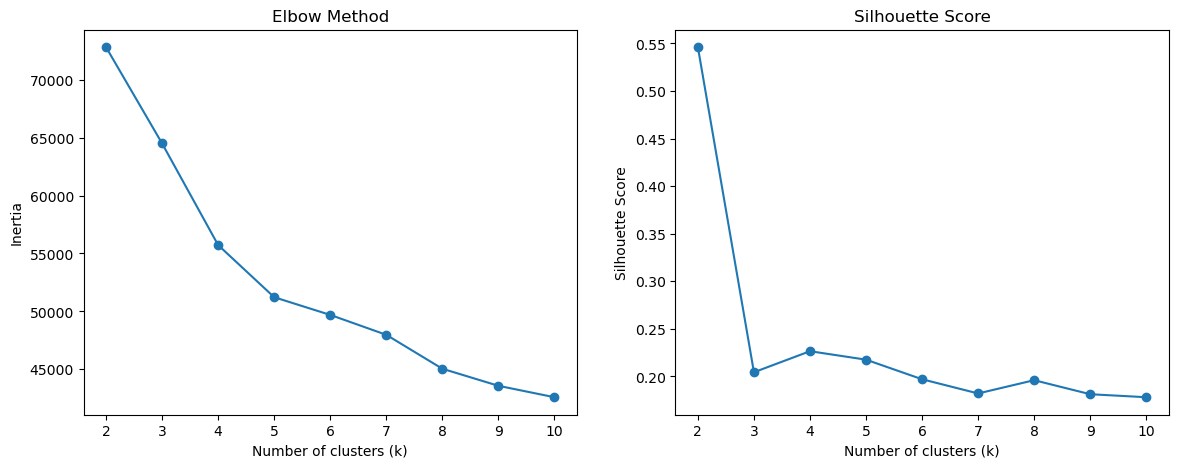

In [509]:
plt.figure(figsize=(14,5))

# Elbow Method
plt.subplot(1,2,1)
plt.plot(K, inertia, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")

# Silhouette Score
plt.subplot(1,2,2)
plt.plot(K, silhouette, marker='o')
plt.title("Silhouette Score")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")

plt.show()

**Berdasarkan grafik Elbow Method, terjadi penurunan inertia yang tajam dari k=2 hingga k=4, kemudian penurunan mulai melandai setelah k≥4. Pola ini menunjukkan bahwa k=4 merupakan titik elbow yang merepresentasikan keseimbangan optimal antara kompleksitas model dan kualitas klasterisasi.**

**Pada grafik Silhouette Score, nilai tertinggi memang muncul pada k=2, namun nilai tersebut cenderung over-simplified karena hanya membagi data menjadi dua kelompok besar. Setelah itu, nilai silhouette relatif stabil pada k=4 dibandingkan k lainnya, menunjukkan struktur klaster yang masih cukup baik dan lebih informatif secara segmentasi.**

**k = 4 dipilih sebagai jumlah cluster optimal, karena Didukung oleh titik elbow yang jelas pada inertia, Silhouette score stabil dan masih representatif, dan Memberikan segmentasi yang lebih bermakna secara analitis dibanding k kecil (k=2)**

**Train Final K-Means**

In [510]:
k_optimal = 4   # sesuaikan dengan hasil grafik

kmeans_final = KMeans(n_clusters=k_optimal, random_state=42)
clusters = kmeans_final.fit_predict(X)

df_clustered = df.copy()
df_clustered['cluster'] = clusters

**Visualisasi Cluster**

PCA projection 2D

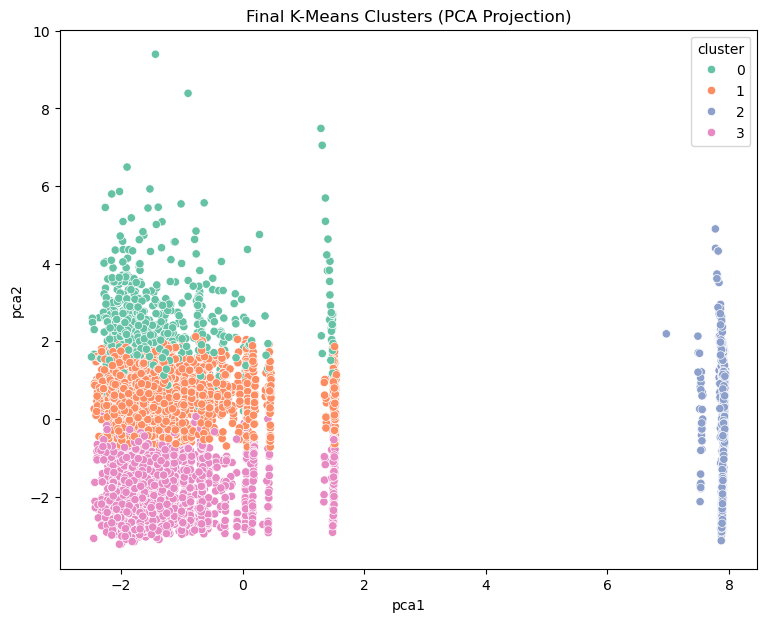

In [511]:
from sklearn.decomposition import PCA
import seaborn as sns

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

df_clustered['pca1'] = X_pca[:,0]
df_clustered['pca2'] = X_pca[:,1]

plt.figure(figsize=(9,7))
sns.scatterplot(
    x='pca1', y='pca2',
    hue='cluster',
    palette='Set2',
    data=df_clustered
)
plt.title("Final K-Means Clusters (PCA Projection)")
plt.show()

**Hasil proyeksi PCA menunjukkan bahwa klaster terbentuk secara jelas, dengan satu klaster terpisah cukup jauh dari kelompok lainnya pada sumbu PCA1, menandakan adanya segmen wilayah dengan karakteristik yang sangat berbeda secara struktural. Sementara klaster lain saling berdekatan namun tetap membentuk pemisahan yang konsisten, menunjukkan adanya variasi karakteristik sosial, demografis, dan infrastruktur antar wilayah.**

**Cluster Profiling**

In [512]:
cluster_profile = df_clustered.groupby('cluster').mean(numeric_only=True)
cluster_profile

,incident_month,incident_week,weekend,precip,visibility,heatindex,male_population,female_population,total_population,gender_ration,average_household_size,literacy_rate,religious_institution,playground,park,police_station,school,college,pca1,pca2
cluster,,,,,,,,,,,,,,,,,,,,
0,6.969655,29.175172,0.282759,30.405241,7.451034,34.070345,2.569823e+05,2.462388e+05,5.032211e+05,101.011034,4.507062,51.883773,722.140690,31.500690,1.677241,4.554483,48.842759,7.972414,-1.319857,2.322016
1,8.106838,34.389546,0.265943,4.075707,9.671269,33.631492,2.846020e+05,2.687891e+05,5.533911e+05,101.656805,4.397906,53.405627,768.280408,34.788626,1.947403,4.341223,50.305062,8.156147,-1.158302,0.606970
2,6.252294,25.564220,0.267202,5.108257,9.566514,32.014908,4.931802e+06,3.974237e+06,8.906039e+06,125.000000,8.420000,73.778236,4289.000000,99.000000,17.000000,59.934633,242.000000,64.000000,7.887280,-0.010190
3,2.855297,9.079070,0.285788,0.921654,9.928682,27.285788,2.698441e+05,2.574142e+05,5.272584e+05,100.800000,4.471199,52.734949,774.525581,33.297674,1.775711,4.422222,49.109044,7.940052,-1.238892,-1.819628


**Hasil clustering K-Means dengan k=4 menunjukkan segmentasi wilayah yang jelas. Cluster 2 merepresentasikan wilayah metropolitan dengan populasi sangat tinggi dan infrastruktur publik yang lengkap. Cluster 0 menggambarkan wilayah urban berkembang dengan kepadatan dan fasilitas publik yang relatif seimbang. Cluster 1 menunjukkan karakteristik wilayah semi-urban sebagai area transisi antara urban dan rural. Sementara itu, Cluster 3 merepresentasikan wilayah rural dengan kepadatan penduduk rendah dan keterbatasan infrastruktur serta fasilitas publik. Segmentasi ini menunjukkan perbedaan struktural antar wilayah yang relevan untuk perencanaan strategi keamanan berbasis wilayah (data-driven policing).**

**Distribusi Kategori Per cluster**

In [513]:
pd.crosstab(df_clustered['cluster'], df_clustered['season'], normalize='index')
pd.crosstab(df_clustered['cluster'], df_clustered['part_of_the_day'], normalize='index')
pd.crosstab(df_clustered['cluster'], df_clustered['crime'], normalize='index')

crime,assault,bodyfound,kidnap,murder,rape,robbery
cluster,,,,,,
0,0.169655,0.195862,0.099310,0.255172,0.216552,0.063448
1,0.164694,0.244576,0.106509,0.210059,0.202827,0.071335
2,0.180046,0.269495,0.076835,0.150229,0.141055,0.182339
3,0.163307,0.204651,0.097158,0.290956,0.152972,0.090956


**Distribusi jenis kejahatan relatif seimbang antar cluster, namun cluster urban (0 dan 2) menunjukkan proporsi lebih tinggi untuk kejahatan berat seperti murder, assault, dan rape, sedangkan cluster rural (3) cenderung memiliki intensitas lebih rendah dan distribusi lebih merata.**

***Thank You***